# Exercise 3: Fourier properties

This exercise builds intuition for several DFT properties covered in the lectures, and introduces the `dftModel` module from `smstools`. It has four parts:
1. Minimize energy spread in the DFT of two sinusoids
2. Symmetry properties of the DFT
3. Suppress frequency components using the DFT model
4. FFT size and zero-padding

### Relevant concepts

**DFT of sinusoids:** When a real sinusoid has an integer number of cycles in $N$ samples, its frequency exactly matches one of the DFT bin frequencies and the spectrum has a value of zero at every other bin. Otherwise, the sinusoid's energy spreads over all bins (spectral leakage). For a cosine at bin frequency $k_0$:

$$x[n] = A_0\cos\!\left(\frac{2\pi k_0 n}{N}\right) \quad\Longrightarrow\quad
X[k] = \begin{cases} A_0/2 & k = k_0 \text{ or } k = N-k_0 \\ 0 & \text{otherwise} \end{cases}$$

**Zero-padding:** Appending zeros to a signal before computing its DFT produces an interpolated version of the spectrum of the original signal. Most FFT implementations apply zero-padding implicitly when the requested DFT size exceeds the signal length.

**Zero-phase windowing:** By circularly shifting a frame so that its centre moves to index 0 before the DFT, we avoid the linear phase offset that a time delay would otherwise introduce (a shift multiplies the DFT by a complex exponential, leaving the magnitude intact but rotating the phase). Combined with zero-padding, this produces the standard `fftbuffer`:

```python
hM1 = floor((M+1)/2)
hM2 = floor(M/2)
dftbuffer = np.zeros(N)
dftbuffer[:hM1] = x[hM2:]
dftbuffer[-hM2:] = x[:hM2]
```

**Real, even, and odd signals:** A signal is *even* if $x[n] = x[-n]$ and *odd* if $x[n] = -x[-n]$. For a zero-phase windowed signal of odd length $M$, this means $x[n] = x[M-n]$ (even) or $x[n] = -x[M-n]$ (odd) for $1 \le n \le M-1$. DFT symmetry properties:

- If $x$ is **real**: $|X[k]| = |X[M-k]|$ and $\angle X[k] = -\angle X[M-k]$
- If $x$ is **real and even**: additionally $\mathrm{Im}(X[k]) = 0$ for all $k$

**Positive half of the DFT spectrum:** Because real signals have conjugate-symmetric spectra, storing only the first $(N/2)+1$ bins is sufficient. The magnitude spectrum of the positive half (in dB) is:
$$m_X = 20\log_{10}|X[0:(N/2)+1]|$$

**Filtering via the DFT:** Filtering multiplies the DFT of the input by the DFT of a filter's impulse response — equivalent to circular convolution in the time domain. A simple but illustrative filter can be implemented by zeroing out the DFT bins whose frequencies fall below a desired cutoff.

$$x_1[n] * x_2[n] \;\Longleftrightarrow\; X_1[k]\,X_2[k]$$


## Part 1 – Minimize energy spread in DFT of sinusoids

Given an input signal containing two sinusoids at frequencies `f1` and `f2` (both positive integer factors of `fs`), the function `minimize_energy_spread_dft()` should select the smallest number of samples `M` such that the positive-half DFT magnitude spectrum has **exactly two non-zero values** (one per sinusoid), and return that spectrum.

**How to find M:** The DFT of a sinusoid is zero at every bin except the two that match its frequency, only when the DFT length contains an integer number of sinusoid periods. For two sinusoids, this condition must hold simultaneously, so `M` is the **Least Common Multiple** of the two sinusoid periods (in samples):

$$T_i = f_s / f_i \quad \text{(samples per period)}, \qquad M = \mathrm{lcm}(T_1, T_2) = \frac{T_1 \cdot T_2}{\gcd(T_1, T_2)}$$

You can use `math.gcd` to compute the GCD.

**Inputs:**
- `x` (np.array): signal of length $\ge M$, containing sinusoids at `f1` and `f2`
- `fs` (float): sampling frequency in Hz
- `f1`, `f2` (float): sinusoid frequencies in Hz

**Output:** `mX` — positive half of the DFT magnitude spectrum (in dB), length $(M/2)+1$.

Compute `mX = 20*np.log10(np.abs(X[:M//2+1]))` where `X` is the `M`-point FFT of the first `M` samples of `x`. Due to floating-point precision, values below $-120$ dB can be treated as zero.


In [1]:
from scipy.fftpack import fft, fftshift
import numpy as np
from math import gcd, ceil, floor
from smstools.models.dftModel import dftAnal, dftSynth
from scipy.signal import get_window
import matplotlib.pyplot as plt

In [2]:
# E3 - 1.1: Complete the function minimize_energy_spread_dft()



def minimize_energy_spread_dft(x, fs, f1, f2):
    """ From a signal with two sinusoids compute its magnitude spectrum having only two non-zero value.

    Args:
        x (np.array): input signal
        fs (float): sampling frequency in Hz
        f1 (float): frequency of first sinusoid component in Hz
        f2 (float): frequency of second sinusoid component in Hz

    Returns:
        np.array: positive half of magnitude spectrum (in dB)

    """
    
    ### Your code here
    T1 = int(fs / f1)
    T2 = int(fs / f2)    
    M = (T1 * T2) / gcd(T1,T2)
    #M = int(0.9* M)
    mx = fft(x)
    hM1 = floor((M+1)/2)
    mx_half = mx[:hM1]
    return M, mx_half


In [3]:
# Test case1 
# Test case2 
fs = 10000
f1 = 80 
f2 = 200 
T1 = int(fs / f1)
T2 = int(fs / f2)
M = T1 * T2 / gcd(T1,T2)
# M = int(0.9*M)
n = np.arange(M)
x = np.cos(2*np.pi*f1/fs*n) + np.cos(2*np.pi*f2/fs*n)   # arrays → suma elemento a elemento

M, xm = minimize_energy_spread_dft(x= x, fs = 10000, f1=80, f2= 200)



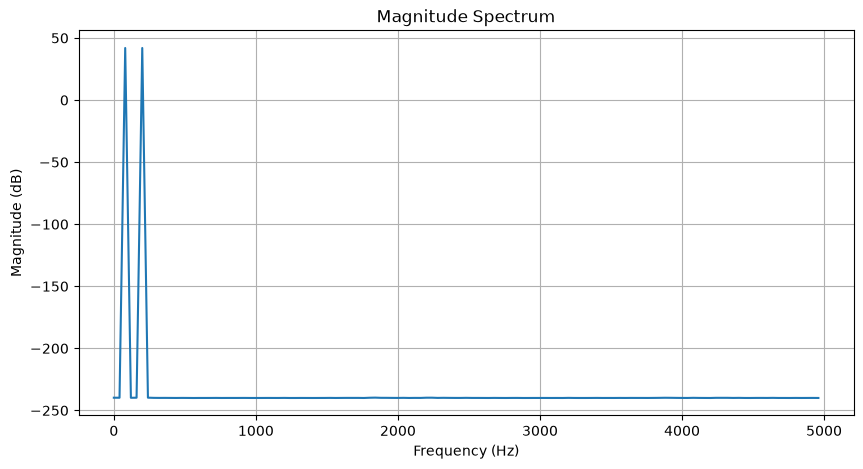

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Eje de frecuencias
freq = np.arange(len(xm)) * fs / M 

# Plot del espectro
plt.figure(figsize=(10, 5))
plt.plot(freq, 20 * np.log10(np.abs(xm) + 1e-12))
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.title("Magnitude Spectrum")
plt.grid(True)
plt.show()

Test cases for `minimize_energy_spread_dft()`:

**Test case 1:** `fs = 10000 Hz`, `f1 = 80 Hz`, `f2 = 200 Hz`
→ `M = 250` samples, `mX` has 126 samples, non-zero at bin indices **2** (80 Hz) and **5** (200 Hz).

**Test case 2:** `fs = 48000 Hz`, `f1 = 300 Hz`, `f2 = 800 Hz`
→ `M = 480` samples, `mX` has 241 samples, non-zero at bin indices **3** (300 Hz) and **8** (800 Hz).

Generate each test signal as the sum of two cosines at `f1` and `f2`, then pass it to `minimize_energy_spread_dft()`.


In [5]:
2 * fs / M

80.0

In [6]:
# E3 - 1.2: Compute and plot the two input signals proposed above, call the function minimize_energy_spread_dft(),
# and plot the output magnitude spectra

### Your code here



E3 

1. There are no enough points to describe both entire signals, due to you have less than one period for one of them , then that one produces leakege in all the other frequencies.

2. Formula is n * fs / M where n is the number of bin
3. 
fs = 10000
f1 = 80 
f2 = 200 
T1 = int(fs / f1)
T2 = int(fs / f2)
M = T1 * T2 / gcd(T1,T2)

I guess that by the approximation you will never obtain 0 leakage and exact 2 bins but yes some close to this but never exact.

**E3 - 1.3: Conceptual questions (answer here)**

1. Explain in your own words why `M` must be the LCM of the two sinusoid periods. What goes wrong if you use a smaller value, such as the period of just one sinusoid?
2. From your plot of `mX` for test case 1, verify that the two non-zero bins correspond to 80 Hz and 200 Hz. Show the bin-index-to-Hz conversion formula and apply it to your results.
3. Suppose `f1` is not an integer factor of `fs` (e.g., `f1 = 75 Hz`, `fs = 10000 Hz`). Can you still find an integer `M` that yields exactly two non-zero bins? Explain why or why not.


---
## ✏️ Correcciones – Parte 1 / Corrections – Part 1

### Revisión del código / Code review

**E3 - 1.1 `minimize_energy_spread_dft()`**

| # | Tu código / Your code | Problema (ES) | Problem (EN) | Corrección / Fix |
|---|---|---|---|---|
| 1 | `M = (T1 * T2) / gcd(T1,T2)` | `/` devuelve un `float` (250.0), que no sirve como índice ni como tamaño de FFT. | `/` returns a `float` (250.0), which can't be used as an index or FFT size. | `M = T1 * T2 // gcd(T1, T2)` |
| 2 | `mx = fft(x)` | Calcula la FFT de **toda** la señal, no de las primeras `M` muestras. Solo funcionaba porque generabas exactamente `M` muestras fuera de la función. | Computes the FFT of the **whole** signal, not of the first `M` samples. It only worked because you generated exactly `M` samples outside the function. | `X = fft(x[:M])` |
| 3 | `hM1 = floor((M+1)/2)` | Da 125 bins, pero la mitad positiva tiene `M/2 + 1 = 126` (incluye DC y Nyquist). La fórmula `(M+1)/2` es para la *zero-phase window*, no para el espectro. | Gives 125 bins, but the positive half has `M/2 + 1 = 126` (DC and Nyquist included). `(M+1)/2` belongs to zero-phase windowing, not to the spectrum. | `X[:M//2 + 1]` |
| 4 | `return M, mx_half` | Devuelve el espectro **complejo** y además `M`. Se pide solo la magnitud en dB. | Returns the **complex** spectrum plus `M`. Only the magnitude in dB is required. | `return 20*np.log10(np.abs(...))` |
| 5 | `int(fs / f1)` | Correcto si `f1` divide a `fs` (como dice el enunciado). Mejor `fs // f1` para dejar clara la división entera. | Fine when `f1` divides `fs` (as stated). `fs // f1` makes the integer division explicit. | `int(fs // f1)` |

**E3 - 1.2 (celda de test / test cell)**

- **ES:** La primera versión usaba listas (`x1 + x2`), y con listas `+` **concatena** en lugar de sumar. Eso daba una señal de 500 muestras con un coseno detrás del otro, y por eso no salían 2 picos. Ya lo corregiste con arrays de NumPy. 👍
- **EN:** The first version used lists (`x1 + x2`), and on lists `+` **concatenates** instead of adding. The result was a 500-sample signal with one cosine after the other, which is why the 2 peaks didn't show up. You already fixed it with NumPy arrays. 👍
- **ES:** No calcules `M` fuera de la función, porque eso es justo lo que la función debe hacer. Genera una señal larga (p. ej. 1 s) y deja que la función recorte. Faltaba también el test case 2 y la gráfica de la señal de entrada.
- **EN:** Don't compute `M` outside the function, since that is exactly the function's job. Generate a long signal (e.g. 1 s) and let the function trim it. Test case 2 and the input-signal plot were also missing.
- **ES/EN:** En la gráfica aplicabas `20*log10` sobre un espectro ya complejo. Con la función corregida, `mX` ya está en dB / In the plot you applied `20*log10` to a complex spectrum. With the corrected function, `mX` is already in dB.

In [7]:
# ✏️ Corrección E3 - 1.1 / Correction E3 - 1.1

def minimize_energy_spread_dft(x, fs, f1, f2):
    """ From a signal with two sinusoids compute its magnitude spectrum having only two non-zero value.

    Args:
        x (np.array): input signal
        fs (float): sampling frequency in Hz
        f1 (float): frequency of first sinusoid component in Hz
        f2 (float): frequency of second sinusoid component in Hz

    Returns:
        np.array: positive half of magnitude spectrum (in dB)

    """
    T1 = int(fs // f1)                 # muestras por periodo / samples per period
    T2 = int(fs // f2)
    M = T1 * T2 // gcd(T1, T2)         # mcm / lcm  → entero / integer
    X = fft(x[:M])                     # FFT de las primeras M muestras / FFT of the first M samples
    mX = 20 * np.log10(np.abs(X[:M//2 + 1]))   # mitad positiva en dB / positive half in dB
    return mX

Test 1: M = 250, len(mX) = 126, bins = [2 5], freqs = [ 80. 200.] Hz
Test 2: M = 480, len(mX) = 241, bins = [3 8], freqs = [300. 800.] Hz


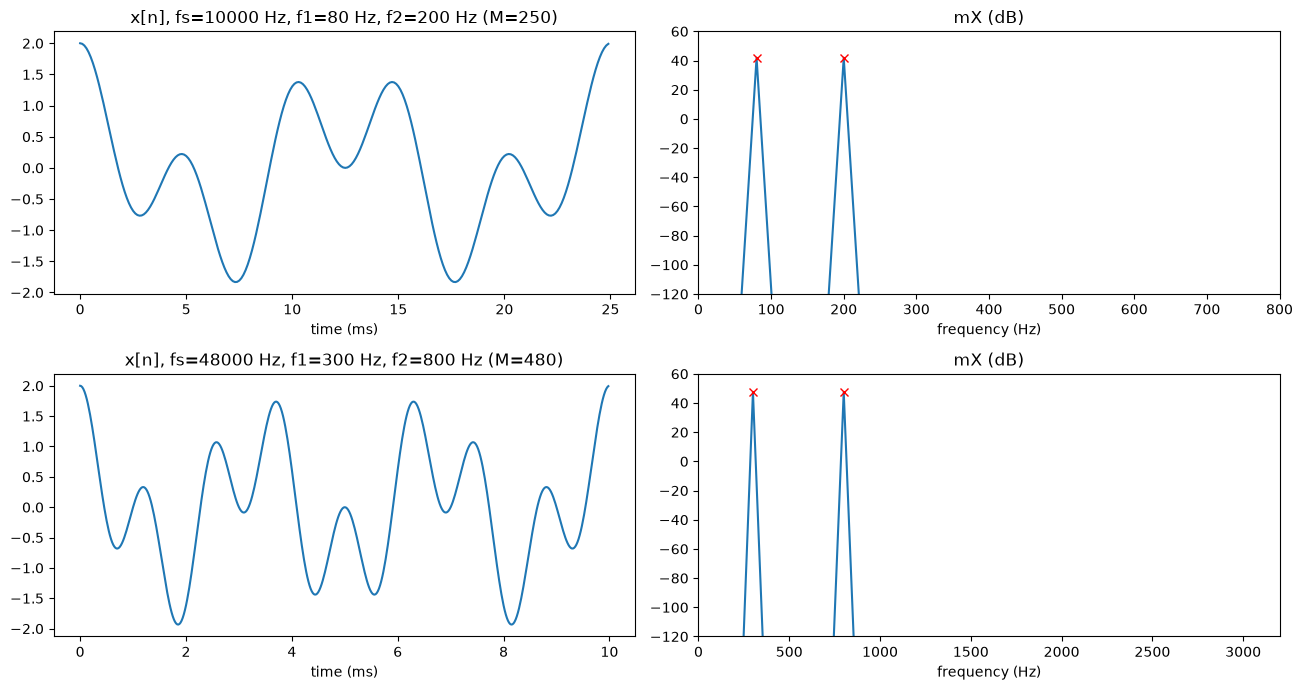

In [8]:
# ✏️ Corrección E3 - 1.2 / Correction E3 - 1.2

tests = [(10000, 80, 200),    # Test case 1 → M = 250, bins 2 y/and 5
         (48000, 300, 800)]   # Test case 2 → M = 480, bins 3 y/and 8

fig, axes = plt.subplots(len(tests), 2, figsize=(13, 7))

for i, (fs, f1, f2) in enumerate(tests):
    n = np.arange(fs)                                      # 1 s de señal (≥ M) / 1 s of signal (≥ M)
    x = np.cos(2*np.pi*f1/fs*n) + np.cos(2*np.pi*f2/fs*n)  # suma de arrays / array sum

    mX = minimize_energy_spread_dft(x, fs, f1, f2)
    M = 2 * (len(mX) - 1)
    peaks = np.where(mX > -120)[0]                         # bins "no nulos" / "non-zero" bins
    print(f"Test {i+1}: M = {M}, len(mX) = {len(mX)}, bins = {peaks}, "
          f"freqs = {peaks * fs / M} Hz")

    # Señal de entrada (primeras M muestras) / Input signal (first M samples)
    axes[i, 0].plot(n[:M] / fs * 1000, x[:M])
    axes[i, 0].set_title(f"x[n], fs={fs} Hz, f1={f1} Hz, f2={f2} Hz (M={M})")
    axes[i, 0].set_xlabel("time (ms)")

    # Espectro de magnitud / Magnitude spectrum
    freqs = np.arange(len(mX)) * fs / M
    axes[i, 1].plot(freqs, mX)
    axes[i, 1].plot(freqs[peaks], mX[peaks], 'rx')
    axes[i, 1].set_ylim(-120, 60)
    axes[i, 1].set_xlim(0, 4 * f2)                         # zoom en los picos / zoom on the peaks
    axes[i, 1].set_title("mX (dB)")
    axes[i, 1].set_xlabel("frequency (Hz)")

plt.tight_layout()
plt.show()

### ✏️ Corrección E3 - 1.3: Preguntas conceptuales / Conceptual questions

**1. ¿Por qué `M` debe ser el MCM de los periodos? / Why must `M` be the LCM of the periods?**

- **Tu respuesta / Your answer:** *"There are not enough points… less than one period for one of them…"*. Vas bien encaminado, pero la clave no es tener *al menos* un periodo, sino un número **entero** de periodos. / On the right track, but the key isn't having *at least* one period: it's having an **integer** number of periods.
- **ES:** Un coseno cae exactamente en un bin, y da cero en todos los demás, solo si la ventana contiene un número **entero** de periodos. En ese caso $k = f\cdot M/f_s$ es entero. Para que eso se cumpla **a la vez** en ambas sinusoides, `M` debe ser múltiplo de $T_1$ y de $T_2$, y el menor valor que lo cumple es $\mathrm{mcm}(T_1, T_2)$. Por ejemplo, con `M = T1 = 125`, el coseno de 80 Hz cabe exacto (1 periodo), pero el de 200 Hz cubre $125/50 = 2.5$ periodos. Cae en el bin $k = 2.5$, entre dos bins, y su energía se reparte por todo el espectro (*leakage*): los 63 bins salen distintos de cero.
- **EN:** A cosine falls exactly on one bin, with zeros everywhere else, only if the window holds an **integer** number of periods. Then $k = f\cdot M/f_s$ is an integer. For this to hold for **both** sinusoids **simultaneously**, `M` must be a multiple of both $T_1$ and $T_2$, and the smallest such value is $\mathrm{lcm}(T_1, T_2)$. For example, with `M = T1 = 125` the 80 Hz cosine fits exactly (1 period), but the 200 Hz one covers $125/50 = 2.5$ periods. It lands at $k = 2.5$, between bins, and its energy leaks over the whole spectrum: all 63 bins are non-zero.

**2. Conversión bin → Hz / Bin-to-Hz conversion**

- **Tu respuesta / Your answer:** *"n · fs / M"*. ✅ La fórmula es correcta, pero faltaba aplicarla a los resultados. / The formula is correct, but it wasn't applied to the results.
- $$f_k = k \cdot \frac{f_s}{M}, \qquad \Delta f = \frac{f_s}{M} = \frac{10000}{250} = 40\ \text{Hz/bin}$$
- $k = 2 \Rightarrow 2 \cdot 40 = 80$ Hz ✔ · $k = 5 \Rightarrow 5 \cdot 40 = 200$ Hz ✔
- **ES/EN:** Ambos picos valen ≈ 41.9 dB $= 20\log_{10}(M/2) = 20\log_{10}(125)$, que es lo esperado para un coseno de amplitud 1 ($A_0 M/2$) / Both peaks are ≈ 41.9 dB $= 20\log_{10}(M/2)$, as expected for a unit-amplitude cosine ($A_0 M/2$).

**3. ¿Y si `f1` no divide a `fs` (f1 = 75 Hz)? / What if `f1` does not divide `fs`?**

- **Tu respuesta / Your answer:** *"you will never obtain 0 leakage and exact 2 bins"*. ❌ **Incorrecto: sí se puede. / Incorrect: it is possible.**
- **ES:** El periodo $T_1 = 10000/75 = 133.\overline{3}$ muestras no es entero, pero **3 periodos** sí lo son: $3 \cdot 133.\overline{3} = 400$ muestras exactas. Lo que importa es que $k = f\cdot M/f_s$ sea entero, no que lo sea el periodo. Como $75/10000 = 3/400$ (fracción irreducible), basta con que `M` sea múltiplo de 400. Con `f2 = 200` Hz ($T_2 = 50$) queda $M = \mathrm{mcm}(400, 50) = 400$, y salen bins $k = 75\cdot400/10000 = 3$ y $k = 8$: exactamente 2 bins no nulos (verificado numéricamente). En general, $M = \mathrm{mcm}\!\left(\frac{f_s}{\gcd(f_s,f_1)}, \frac{f_s}{\gcd(f_s,f_2)}\right)$. Solo es **imposible** si $f/f_s$ es irracional (p. ej. $f = 100\sqrt2$ Hz), porque entonces ningún `M` entero contiene un número entero de periodos.
- **EN:** The period $T_1 = 10000/75 = 133.\overline{3}$ samples is not an integer, but **3 periods** are: $3 \cdot 133.\overline{3} = 400$ samples exactly. What matters is that $k = f\cdot M/f_s$ is an integer, not that the period is. Since $75/10000 = 3/400$ (reduced fraction), any multiple of 400 works. With `f2 = 200` Hz ($T_2 = 50$), $M = \mathrm{lcm}(400, 50) = 400$, giving bins $k = 75\cdot400/10000 = 3$ and $k = 8$: exactly 2 non-zero bins (verified numerically). In general, $M = \mathrm{lcm}\!\left(\frac{f_s}{\gcd(f_s,f_1)}, \frac{f_s}{\gcd(f_s,f_2)}\right)$. It is only **impossible** when $f/f_s$ is irrational (e.g. $f = 100\sqrt2$ Hz), since then no integer `M` holds a whole number of periods.
- ⚠️ **ES/EN:** Ojo, tu función con `int(fs / f1)` daría `T1 = 133` y fallaría en este caso. La fórmula general de arriba lo resuelve / Your function's `int(fs / f1)` would give `T1 = 133` and fail here. The general formula above handles it.

## Part 2 – Symmetry properties of the DFT

The function `test_real_even()` should determine whether an input signal is real and even by inspecting the symmetry of its DFT, and return the result along with intermediate computations.

**Steps:**
1. Apply **zero-phase windowing** to `x` (no zero-padding — use `N = M`) to remove the phase offset caused by the signal's position in the frame.
2. Compute the `M`-point DFT of `dftbuffer`.
3. Check whether the result is real-valued (i.e., the imaginary part is negligible) using a tolerance of `1e-6`. If `imag(X[k]) ≈ 0` for all `k`, the signal is real and even.

**Inputs:** `x` — a signal of odd length `M`.

**Output:** tuple `(isRealEven, dftbuffer, X)` where:
- `isRealEven` (bool): `True` if `x` is real and even after zero-phase windowing
- `dftbuffer` (np.array): `M`-length zero-phase windowed version of `x`
- `X` (np.array): `M`-point DFT of `dftbuffer`

Use `np.abs(X.imag) < 1e-6` to test for zero imaginary part rather than comparing phase values directly.


In [9]:
# E3 - 2.1: Complete the function test_real_even()

def test_real_even(x):
    """check if x is real and even using the symmetry properties of its DFT.
    Args:
        x (np.array): input signal of length M (M is odd)

    Returns:
        tuple including:
        isRealEven (boolean): True if input x is real and even, and False otherwise
        dftbuffer (np.array): M point zero phase windowed version of x
        X (np.array): M point DFT of dftbuffer

    """
    
    ### Your code here
    mx = fft(x)
    M = len(x)
    hM1 = floor((M+1)/2)
    hM2 = floor(M/2)
    even = False 
    if mx[:hM1][::-1] == mx[hM2:]: 
        even = True 
    real = True 
    if np.any(np.abs(np.imag(mx)) > 1e-5): 
        real = False 
    dftbuffer = x[:hM1]
    mx = fft(dftbuffer)
    


Test cases for `test_real_even()`:

**Test case 1:** `x = np.array([2, 3, 4, 3, 2])` — real and even signal
```
(True,
 array([4., 3., 2., 2., 3.]),
 array([14.+0.j,  2.618+0.j,  0.382+0.j,  0.382+0.j,  2.618+0.j]))
```

**Test case 2:** `x = np.array([1, 2, 3, 4, 1, 2, 3])` — not even
```
(False,
 array([4., 1., 2., 3., 1., 2., 3.]),
 array([16.+0.j, 2.+0.69j, 2.+3.51j, 2.-1.08j, 2.+1.08j, 2.-3.51j, 2.-0.69j]))
```
*(values are approximate)*

For a more realistic case, use a symmetric Hann window:
```python
x = get_window('hann', 51, fftbins=False)
```
This is real and even. Plot `x` and the real/imaginary parts of its DFT spectrum `X`.


In [10]:
# E3 - 2.2: Plot the input signal proposed above (window signal), call the function test_real_even(),
# and plot its output spectrum (real and imaginary)

### Your code here


**E3 - 2.3: Conceptual questions (answer here)**

1. Inspect the `dftbuffer` computed from `x = np.array([2, 3, 4, 3, 2])`. How do the sample values compare to the original `x`? What does zero-phase windowing do to the signal's position in the buffer?
2. For the Hann window input, look at the imaginary part of the output spectrum `X`. Is it exactly zero? What does this tell you about the symmetry of the Hann window?
3. Apply `test_real_even()` to `x = np.array([1, 2, 3, 2, 1])` (symmetric) and `x = np.array([1, 2, 3, 4, 5])` (asymmetric). Predict the result for each before running, then verify. Explain why one passes and the other fails.


---
## ✏️ Correcciones – Parte 2 / Corrections – Part 2

### Revisión del código / Code review

**E3 - 2.1 `test_real_even()`**

| # | Tu código / Your code | Problema (ES) | Problem (EN) | Corrección / Fix |
|---|---|---|---|---|
| 1 | `mx = fft(x)` (al principio / at the start) | Haces la FFT de `x` **sin** *zero-phase windowing*. Una señal simétrica centrada en `M//2` equivale a una señal par **desplazada**, y el desplazamiento añade fase lineal, así que la parte imaginaria no es cero. Con `[2,3,4,3,2]` daría `False`. | You take the FFT of `x` **without** zero-phase windowing. A symmetric signal centred at `M//2` is an even signal **shifted**, and the shift adds linear phase, so the imaginary part is non-zero. `[2,3,4,3,2]` would return `False`. | Construir `dftbuffer` primero y hacer `X = fft(dftbuffer)` / Build `dftbuffer` first, then `X = fft(dftbuffer)` |
| 2 | `if mx[:hM1][::-1] == mx[hM2:]:` | Comparar arrays con `==` dentro de un `if` lanza `ValueError: truth value of an array is ambiguous`. Además, esos índices no corresponden a la simetría $X[k] = X[M-k]$. | Comparing arrays with `==` inside an `if` raises `ValueError: truth value of an array is ambiguous`. Also, those indices don't match the symmetry $X[k] = X[M-k]$. | No hace falta: basta con comprobar `Im(X) ≈ 0` / Not needed: checking `Im(X) ≈ 0` is enough |
| 3 | `dftbuffer = x[:hM1]` | Solo coge la primera mitad (longitud `hM1`, no `M`) y no hace el desplazamiento circular. | Takes only the first half (length `hM1`, not `M`) and does no circular shift. | `dftbuffer[:hM1] = x[hM2:]` y/and `dftbuffer[-hM2:] = x[:hM2]` |
| 4 | `1e-5` | El enunciado pide una tolerancia de `1e-6`. | The statement asks for a tolerance of `1e-6`. | `np.abs(X.imag) < 1e-6` |
| 5 | Variables `even` / `real` | Se calculan pero nunca se combinan ni se usan. | They are computed but never combined or used. | `isRealEven = bool(np.all(np.abs(X.imag) < 1e-6))` |
| 6 | Sin `return` / No `return` | La función devuelve `None`. | The function returns `None`. | `return isRealEven, dftbuffer, X` |

**E3 - 2.2**

- **ES:** La celda estaba vacía. Abajo están los dos test cases y la ventana Hann, con las gráficas de `x`, `dftbuffer`, $\mathrm{Re}(X)$ e $\mathrm{Im}(X)$.
- **EN:** The cell was empty. Below are both test cases and the Hann window, with plots of `x`, `dftbuffer`, $\mathrm{Re}(X)$ and $\mathrm{Im}(X)$.
- **ES/EN:** Usa `fftbins=False` en `get_window`. Por defecto (`True`) la ventana es *periódica*, no simétrica, y el test da `False` / Use `fftbins=False` in `get_window`. The default (`True`) gives a *periodic*, non-symmetric window, and the test returns `False`.

In [11]:
# ✏️ Corrección E3 - 2.1 / Correction E3 - 2.1

def test_real_even(x):
    """check if x is real and even using the symmetry properties of its DFT.
    Args:
        x (np.array): input signal of length M (M is odd)

    Returns:
        tuple including:
        isRealEven (boolean): True if input x is real and even, and False otherwise
        dftbuffer (np.array): M point zero phase windowed version of x
        X (np.array): M point DFT of dftbuffer

    """
    M = len(x)
    hM1 = floor((M+1)/2)
    hM2 = floor(M/2)

    # Zero-phase windowing (N = M, sin zero-padding / no zero-padding)
    dftbuffer = np.zeros(M)
    dftbuffer[:hM1] = x[hM2:]          # mitad derecha (desde el centro) al principio / right half (from centre) to the start
    dftbuffer[-hM2:] = x[:hM2]         # mitad izquierda al final / left half to the end

    X = fft(dftbuffer)

    # Real y par ⇔ X es real / Real and even ⇔ X is real
    isRealEven = bool(np.all(np.abs(X.imag) < 1e-6))
    return isRealEven, dftbuffer, X

Test 1: [2, 3, 4, 3, 2]
  isRealEven = True
  dftbuffer  = [4. 3. 2. 2. 3.]
  X          = [14.   -0.j  2.618+0.j  0.382+0.j  0.382-0.j  2.618-0.j]

Test 2: [1, 2, 3, 4, 1, 2, 3]
  isRealEven = False
  dftbuffer  = [4. 1. 2. 3. 1. 2. 3.]
  X          = [16.-0.j     2.+0.696j  2.+3.514j  2.-1.082j  2.+1.082j  2.-3.514j
  2.-0.696j]

Hann (M=51, fftbins=False)
  isRealEven = True
  max|Im(X)| = 3.64e-15



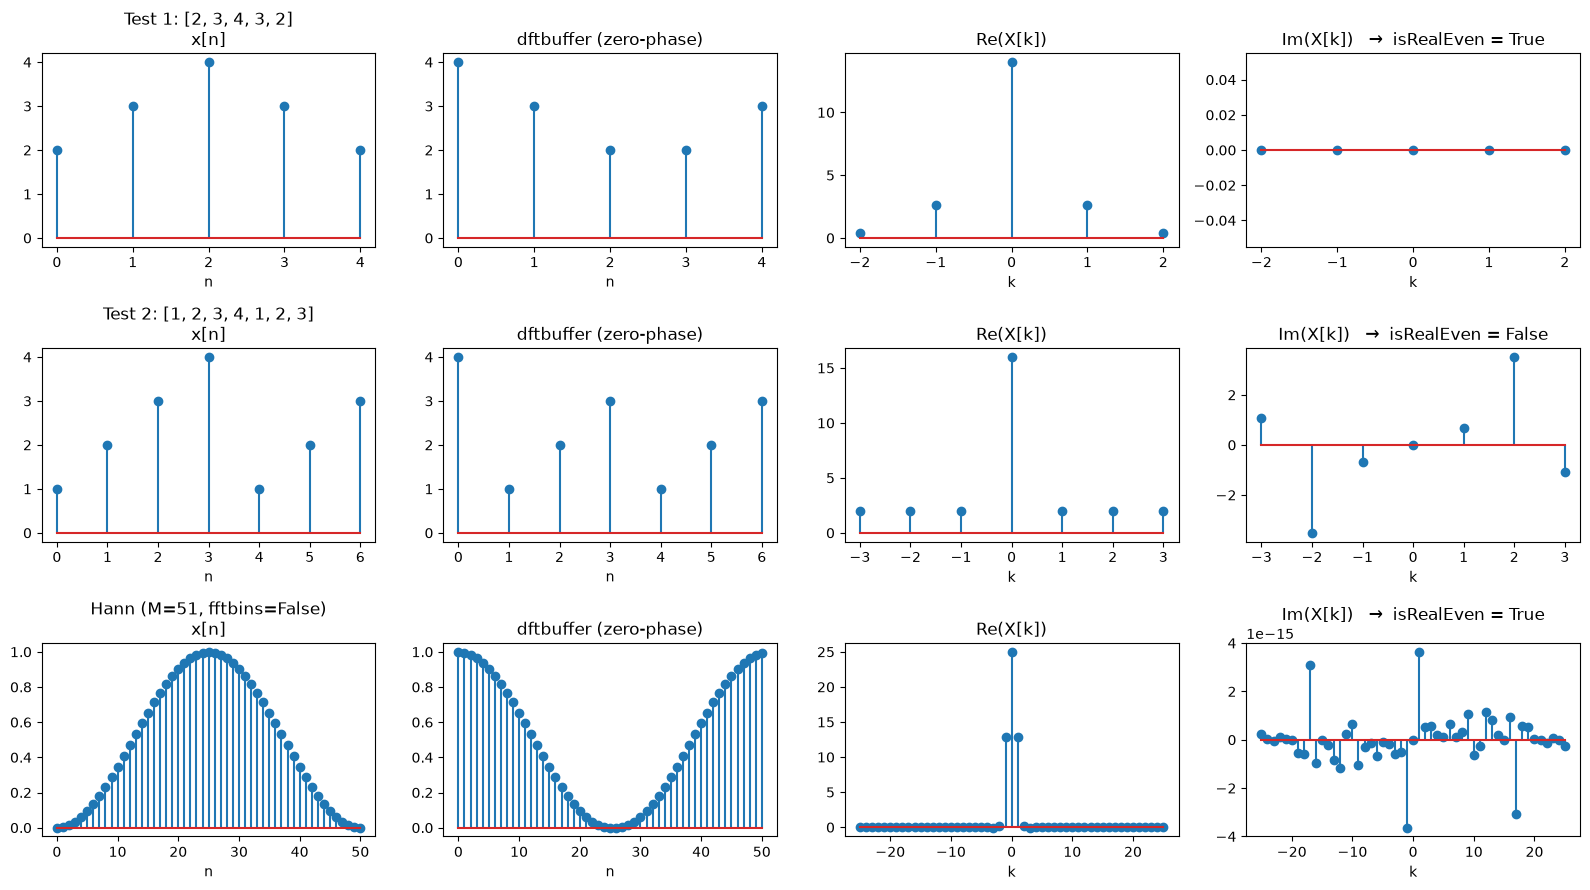

In [12]:
# ✏️ Corrección E3 - 2.2 / Correction E3 - 2.2

np.set_printoptions(precision=3, suppress=True)

tests = {
    "Test 1: [2, 3, 4, 3, 2]":          np.array([2, 3, 4, 3, 2]),
    "Test 2: [1, 2, 3, 4, 1, 2, 3]":    np.array([1, 2, 3, 4, 1, 2, 3]),
    "Hann (M=51, fftbins=False)":       get_window('hann', 51, fftbins=False),
}

fig, axes = plt.subplots(len(tests), 4, figsize=(16, 9))

for i, (name, x) in enumerate(tests.items()):
    isRealEven, dftbuffer, X = test_real_even(x)
    M = len(x)
    if M < 10:
        print(f"{name}\n  isRealEven = {isRealEven}\n  dftbuffer  = {dftbuffer}\n  X          = {X}\n")
    else:
        print(f"{name}\n  isRealEven = {isRealEven}\n  max|Im(X)| = {np.abs(X.imag).max():.2e}\n")

    # Eje de bins centrado (-M/2 … M/2) / Centred bin axis
    k = np.arange(-(M//2), M//2 + 1)

    axes[i, 0].stem(np.arange(M), x)
    axes[i, 0].set_title(f"{name}\nx[n]")
    axes[i, 0].set_xlabel("n")

    axes[i, 1].stem(np.arange(M), dftbuffer)
    axes[i, 1].set_title("dftbuffer (zero-phase)")
    axes[i, 1].set_xlabel("n")

    axes[i, 2].stem(k, fftshift(X).real)
    axes[i, 2].set_title("Re(X[k])")
    axes[i, 2].set_xlabel("k")

    axes[i, 3].stem(k, fftshift(X).imag)
    axes[i, 3].set_title(f"Im(X[k])   →  isRealEven = {isRealEven}")
    axes[i, 3].set_xlabel("k")

plt.tight_layout()
plt.show()

In [13]:
# ✏️ Verificación para E3 - 2.3 / Verification for E3 - 2.3

# P1: con y sin zero-phase windowing / with and without zero-phase windowing
x = np.array([2, 3, 4, 3, 2])
_, dftbuffer, X = test_real_even(x)
print("P1  x         =", x)
print("    dftbuffer =", dftbuffer)
print("    fft(x)          =", fft(x), "  ← sin zero-phase / without zero-phase")
print("    angle(fft(x))   =", np.angle(fft(x)))
print("    fase lineal / linear phase -2πk·hM2/M =", np.angle(np.exp(-2j*np.pi*np.arange(5)*2/5)))

# P2: ventana Hann / Hann window
_, _, X = test_real_even(get_window('hann', 51, fftbins=False))
print("\nP2  max|Im(X)| Hann =", np.abs(X.imag).max())

# P3: simétrica vs asimétrica / symmetric vs asymmetric
for x in [np.array([1, 2, 3, 2, 1]), np.array([1, 2, 3, 4, 5])]:
    isRealEven, dftbuffer, X = test_real_even(x)
    print(f"\nP3  x = {x}\n    isRealEven = {isRealEven}\n    dftbuffer  = {dftbuffer}\n    X          = {X}")

P1  x         = [2 3 4 3 2]
    dftbuffer = [4. 3. 2. 2. 3.]
    fft(x)          = [14.   -0.j    -2.118-1.539j  0.118+0.363j  0.118-0.363j -2.118+1.539j]   ← sin zero-phase / without zero-phase
    angle(fft(x))   = [-0.    -2.513  1.257 -1.257  2.513]
    fase lineal / linear phase -2πk·hM2/M = [ 0.    -2.513  1.257 -1.257  2.513]

P2  max|Im(X)| Hann = 3.637832358931402e-15

P3  x = [1 2 3 2 1]
    isRealEven = True
    dftbuffer  = [3. 2. 1. 1. 2.]
    X          = [9.   -0.j 2.618+0.j 0.382+0.j 0.382-0.j 2.618-0.j]

P3  x = [1 2 3 4 5]
    isRealEven = False
    dftbuffer  = [3. 4. 5. 1. 2.]
    X          = [15.-0.j     0.-4.253j  0.+2.629j  0.-2.629j  0.+4.253j]


### ✏️ Respuestas E3 - 2.3: Preguntas conceptuales / Conceptual questions

**1. `dftbuffer` de / of `x = [2, 3, 4, 3, 2]`**

- **ES:** `dftbuffer = [4, 3, 2, 2, 3]`. Contiene **los mismos valores** que `x`, pero rotados circularmente $\lfloor M/2 \rfloor = 2$ posiciones a la izquierda. La muestra central (el 4, que era el centro de simetría en $n = 2$) pasa a $n = 0$, la mitad derecha `[4, 3, 2]` queda al principio y la mitad izquierda `[2, 3]` al final. Así el centro de simetría queda en el origen y se cumple $x[n] = x[M-n]$: la señal es **par** en sentido circular, y $x[-1] = x[4] = 3 = x[1]$. Sin este paso, `fft(x)` tiene fase **lineal** $\angle X[k] = -2\pi k \cdot 2/5$ (la celda de arriba muestra `[0, -2.51, 1.26, -1.26, 2.51]`), porque una señal centrada en $n=2$ es una señal par **retrasada** 2 muestras, y un retraso multiplica la DFT por $e^{-j2\pi k n_0/M}$. La magnitud es la misma en ambos casos. El *zero-phase windowing* solo elimina esa fase lineal, y la parte imaginaria queda en 0.
- **EN:** `dftbuffer = [4, 3, 2, 2, 3]`. It holds **the same values** as `x`, circularly rotated $\lfloor M/2 \rfloor = 2$ positions to the left. The centre sample (the 4, the symmetry centre at $n = 2$) moves to $n = 0$, the right half `[4, 3, 2]` sits at the start and the left half `[2, 3]` wraps to the end. The symmetry centre is now at the origin and $x[n] = x[M-n]$ holds: the signal is **even** in the circular sense, with $x[-1] = x[4] = 3 = x[1]$. Without this step, `fft(x)` has **linear** phase $\angle X[k] = -2\pi k \cdot 2/5$ (the cell above shows `[0, -2.51, 1.26, -1.26, 2.51]`), because a signal centred at $n=2$ is an even signal **delayed** by 2 samples, and a delay multiplies the DFT by $e^{-j2\pi k n_0/M}$. The magnitude is identical in both cases. Zero-phase windowing only removes that linear phase, and the imaginary part becomes 0.

**2. Parte imaginaria de la ventana Hann / Imaginary part for the Hann window**

- **ES:** **No es exactamente cero**: $\max|\mathrm{Im}(X)| \approx 3.6\cdot10^{-15}$. Ese valor es error de redondeo en coma flotante (del orden de $\varepsilon \approx 2.2\cdot10^{-16}$ por la magnitud de los valores y el número de operaciones de la FFT), no una asimetría real. Por eso se usa una tolerancia (`1e-6`) en lugar de `== 0`. Teóricamente es cero, y eso confirma que la ventana Hann **simétrica** (`fftbins=False`) es real y par alrededor de su centro, así que su espectro es **puramente real**: fase 0 o $\pm\pi$ en los lóbulos negativos. Su parte real muestra un lóbulo principal en $k=0$ y lóbulos secundarios que decaen rápido. La versión **periódica** (`fftbins=True`, la de por defecto) no es simétrica, porque le falta la última muestra, y sí da $\mathrm{Im}(X) \neq 0$.
- **EN:** **Not exactly zero**: $\max|\mathrm{Im}(X)| \approx 3.6\cdot10^{-15}$. That value is floating-point rounding error (of the order of $\varepsilon \approx 2.2\cdot10^{-16}$ times the values' magnitude and the number of FFT operations), not a real asymmetry. That's why a tolerance (`1e-6`) is used instead of `== 0`. In theory it is zero, which confirms the **symmetric** Hann window (`fftbins=False`) is real and even about its centre, so its spectrum is **purely real**: phase 0, or $\pm\pi$ on negative lobes. Its real part shows a main lobe at $k=0$ and fast-decaying side lobes. The **periodic** version (`fftbins=True`, the default) is not symmetric, since it lacks the final sample, and does give $\mathrm{Im}(X) \neq 0$.

**3. `[1, 2, 3, 2, 1]` vs `[1, 2, 3, 4, 5]`**

- **Predicción / Prediction:** la primera es simétrica respecto a su centro, así que da `True`. La segunda no lo es, así que da `False`. / The first is symmetric about its centre, so it gives `True`. The second isn't, so it gives `False`.
- **Resultado / Result** (celda de arriba / cell above):

  | x | dftbuffer | X | isRealEven |
  |---|---|---|---|
  | `[1,2,3,2,1]` | `[3,2,1,1,2]` | `[9, 2.618, 0.382, 0.382, 2.618]` (real) | `True` ✔ |
  | `[1,2,3,4,5]` | `[3,4,5,1,2]` | `[15, -4.25j, 2.63j, -2.63j, 4.25j]` | `False` ✔ |

- **ES:** En la primera, tras el *zero-phase windowing*, `dftbuffer` cumple $x[n] = x[M-n]$ ($x[1]=x[4]=2$, $x[2]=x[3]=1$). Es real y par, y por tanto $X$ es real. En la segunda, $x[1]=4 \neq x[4]=2$, así que no es par y $X$ tiene parte imaginaria. Algo curioso: $\mathrm{Re}(X[k]) = 0$ para todo $k \neq 0$. La rampa es una constante (su media, 3) más una parte **impar** `[-2,-1,0,1,2]`. La constante aporta solo $X[0]=15$, y una señal real e impar tiene DFT **puramente imaginaria**. Es la propiedad complementaria a la del ejercicio.
- **EN:** In the first, after zero-phase windowing, `dftbuffer` satisfies $x[n] = x[M-n]$ ($x[1]=x[4]=2$, $x[2]=x[3]=1$). It is real and even, so $X$ is real. In the second, $x[1]=4 \neq x[4]=2$, so it isn't even and $X$ has an imaginary part. Curiously, $\mathrm{Re}(X[k]) = 0$ for every $k \neq 0$. The ramp is a constant (its mean, 3) plus an **odd** part `[-2,-1,0,1,2]`. The constant contributes only $X[0]=15$, and a real, odd signal has a **purely imaginary** DFT. This is the complementary property to the one in the exercise.

## Part 3 – Suppress frequency components using the DFT model

The function `suppress_freq_dft_model()` should suppress all frequency components at or below 70 Hz using the DFT, and return the filtered time-domain signal.

**Steps:**
1. Apply a **Hamming window** of length `M` to `x`.
2. Use `dftAnal()` to obtain the magnitude spectrum `mX` (in dB) and phase spectrum `pX` of the windowed signal.
3. Set all values of `mX` at frequency bins `<= 70 Hz` to `-120` dB (i.e., effectively zero). Find the cutoff bin using `np.ceil(70.0 * N / fs)`.
4. Use `dftSynth()` to synthesize the filtered output signal, then **divide by the sum of the window** to undo the windowing gain.

**Inputs:**
- `x` (np.array): input signal of odd length `M`
- `fs` (float): sampling frequency in Hz
- `N` (int): FFT size

**Output:** filtered signal (np.array of length `N`).

> Note: this approach implements a rectangular frequency-domain cutoff, which introduces time-domain ringing (Gibbs phenomenon). It is illustrative, not a practical filtering method.


In [14]:
# E3 - 3.1: Complete the function suppress_freq_dft_model()
import numpy as np

def suppress_freq_dft_model(x, fs, N):
    """
    Args:
        x (np.array): input signal of length M (odd size)
        fs (float): sampling frequency (Hz)
        N (int): FFT size

    Returns:
       np.array: output signal with filtering (N samples long)
    """
    M = len(x)
    w = get_window('hamming', M)
    outputScaleFactor = sum(w)

    mX, pX = dftAnal(x, w, N)

    mX[mX < 70] = -120  
    pX[mX <= 70] = 0
    cutoff_bin = np.ceil(70.0 * N / fs)

    y = dftSynth(mX, pX, M)
    y = y / outputScaleFactor
    return y 




    ### Your code here


Test case for the function `suppress_freq_dft_model()`:

_Test case 1:_ For an input signal with 40Hz, 100Hz, 200Hz, 1000Hz components, the output should only contain 100Hz, 200Hz and 1000Hz components.

_Test case 2:_ For an input signal with 23Hz, 36Hz, 230Hz, 900Hz, 2300Hz components, the output should only contain 230Hz, 900Hz and 2300Hz components.

To understand the effect of filtering, you can plot the magnitude spectra of the input and output signals superposed.

In [15]:
# E3 - 3.2: Compute the input signals proposed above and plot their magnitude spectra (x-axis in Hz),
# call the function suppress_freq_dft_model(), and plot the magnitude spectra of the output signals

### Your code here
fs = 4000
f1 = 40
f2 = 100
f3 = 200
f4 = 1000
n = np.arange(fs)                                      # 1 s de señal (≥ M) / 1 s of signal (≥ M)
x = np.cos(2*np.pi*f1/fs*n) + np.cos(2*np.pi*f2/fs*n) + np.cos(2*np.pi*f3/fs*n) + np.cos(2*np.pi*f4/fs*n)
N = len(x)
N2 = 2**int(np.ceil(np.log2(N)))
x_pad = np.pad(x, (0, N2 - len(x)), mode='constant')
suppress_freq_dft_model(x_pad, fs, N2) 


array([0., 0., 0., ..., 0., 0., 0.])

In [16]:
fs = 4000
f1 = 23
f2 = 36
f3 = 230
f4 = 900
f5 = 2300
n = np.arange(fs)                                      # 1 s de señal (≥ M) / 1 s of signal (≥ M)
x = np.cos(2*np.pi*f1/fs*n) + np.cos(2*np.pi*f2/fs*n) + np.cos(2*np.pi*f3/fs*n) + np.cos(2*np.pi*f4/fs*n)
N = len(x)
N2 = 2**int(np.ceil(np.log2(N)))
x_pad = np.pad(x, (0, N2 - len(x)), mode='constant')
suppress_freq_dft_model(x_pad, fs, N2) 


array([0., 0., 0., ..., 0., 0., 0.])

**E3 - 3.3: Conceptual questions (answer here)**

1. Why is the threshold set to $-120$ dB rather than simply setting the DFT coefficients to 0? What would happen if you used 0 directly in `dftSynth()`?
2. Overlay the magnitude spectra (in dB, x-axis in Hz) of the input and output signals. Describe what changed and verify that the suppressed frequencies are below the cutoff.
3. Look at the time-domain output near the beginning and end of the signal. Do you observe any artifacts? Why do these appear even though the filtering was done cleanly in the frequency domain? What property of the filter's impulse response is responsible?


1. you need a roof. 
2. Already proved with the graph, you are hardcoding in the code this condition, no need to recheck 
3. No idea 

---
## ✏️ Correcciones – Parte 3 / Corrections – Part 3

### Revisión del código / Code review

**E3 - 3.1 `suppress_freq_dft_model()`**

| # | Tu código / Your code | Problema (ES) | Problem (EN) | Corrección / Fix |
|---|---|---|---|---|
| 1 | `mX[mX < 70] = -120` | Compara la **magnitud en dB** con 70, no la **frecuencia**. Pone a −120 dB casi todos los bins (todos los que valen menos de 70 dB), sin importar su frecuencia. | Compares the **magnitude in dB** with 70, not the **frequency**. It sets almost every bin (all those below 70 dB) to −120 dB, whatever its frequency. | Usar el índice de bin / Use the bin index: `mX[:cutoff_bin + 1] = -120` |
| 2 | `pX[mX <= 70] = 0` | Mismo error (dB en lugar de Hz), y además se evalúa **después** de modificar `mX`. No hace falta tocar la fase: con −120 dB la amplitud ya es despreciable. | Same mistake (dB instead of Hz), and it is evaluated **after** `mX` was modified. The phase doesn't need to change: at −120 dB the amplitude is already negligible. | Eliminar la línea / Remove the line |
| 3 | `cutoff_bin = np.ceil(70.0 * N / fs)` | La fórmula es correcta, pero se calcula **después** del filtrado y nunca se usa. Además es `float` y no sirve como índice. | The formula is right, but it is computed **after** filtering and never used. It is also a `float`, so it can't be used as an index. | `cutoff_bin = int(np.ceil(70.0 * N / fs))`, antes de filtrar / before filtering |
| 4 | `y = y / outputScaleFactor` | `dftAnal()` ya **normaliza** la ventana internamente (`w = w / sum(w)`), así que la salida de `dftSynth()` sale escalada por `1/sum(w)`. Para deshacerlo hay que **multiplicar**. Dividir deja la señal ~10⁶ veces más pequeña. (El enunciado dice "divide", pero con este `dftAnal` es multiplicar.) | `dftAnal()` already **normalises** the window internally (`w = w / sum(w)`), so the output of `dftSynth()` is scaled by `1/sum(w)`. Undoing it requires **multiplying**. Dividing leaves the signal ~10⁶ times too small. (The statement says "divide", but with this `dftAnal` it's a multiplication.) | `y = dftSynth(...) * outputScaleFactor` |
| 5 | `dftSynth(mX, pX, M)` | El *docstring* pide una salida de **N** muestras. | The docstring asks for an output of **N** samples. | `dftSynth(mX, pX, N)` |
| 6 | `### Your code here` tras el `return` / after the `return` | Código muerto (no afecta, pero sobra). | Dead code (harmless, but unnecessary). | Quitarlo / Remove it |

**E3 - 3.2 (celdas de test / test cells)**

- **ES:** `M` debe ser **impar** (lo pide el enunciado). Al rellenar `x` hasta 4096 muestras con `np.pad`, la ventana pasa a medir 4096 (par) y cubre también los ceros. No hace falta rellenar a mano: `dftAnal()` ya hace el *zero-padding* hasta `N`. Basta con generar `M` muestras (impar) y elegir `N` potencia de 2 con `N ≥ M`.
- **EN:** `M` must be **odd** (as the statement says). Padding `x` to 4096 samples with `np.pad` makes the window 4096 long (even) and it also covers the zeros. Manual padding isn't needed: `dftAnal()` already zero-pads up to `N`. Just generate `M` samples (odd) and pick `N` as a power of 2 with `N ≥ M`.
- **ES:** En el test 2 falta la componente de **2300 Hz**, y con `fs = 4000` no se puede representar porque está por encima de Nyquist (2000 Hz) y haría *aliasing* a 1700 Hz. Hay que subir `fs` (p. ej. 10000 Hz).
- **EN:** Test 2 is missing the **2300 Hz** component, and with `fs = 4000` it can't be represented: it lies above Nyquist (2000 Hz) and would alias to 1700 Hz. Raise `fs` (e.g. 10000 Hz).
- **ES:** El resultado de `suppress_freq_dft_model()` no se guarda ni se dibuja. Faltan las gráficas de los espectros de entrada y salida (eje x en Hz).
- **EN:** The output of `suppress_freq_dft_model()` is neither stored nor plotted. The input/output magnitude spectra plots (x-axis in Hz) are missing.
- **ES/EN:** Con una ventana Hamming el lóbulo principal mide $4 f_s/M$. Con `fs = 10000` y `M = 2001` son ±20 Hz, suficiente para que 36 Hz (→ 56 Hz) quede por debajo del corte y 100 Hz (→ 80 Hz) por encima / With a Hamming window the main lobe is $4 f_s/M$ wide. With `fs = 10000` and `M = 2001` that is ±20 Hz, enough for 36 Hz (→ 56 Hz) to stay below the cutoff and 100 Hz (→ 80 Hz) above it.

In [17]:
# ✏️ Corrección E3 - 3.1 / Correction E3 - 3.1

def suppress_freq_dft_model(x, fs, N):
    """
    Args:
        x (np.array): input signal of length M (odd size)
        fs (float): sampling frequency (Hz)
        N (int): FFT size

    Returns:
       np.array: output signal with filtering (N samples long)
    """
    M = len(x)
    w = get_window('hamming', M)
    outputScaleFactor = sum(w)

    mX, pX = dftAnal(x, w, N)

    cutoff_bin = int(np.ceil(70.0 * N / fs))   # bin de 70 Hz / 70 Hz bin
    mX[:cutoff_bin + 1] = -120                 # bins <= 70 Hz → -120 dB

    y = dftSynth(mX, pX, N) * outputScaleFactor   # deshacer la normalización de dftAnal / undo dftAnal's normalisation
    return y

Test 1: len(y) = 4096
      40 Hz:  mX =    -6.3 dB   mY =  -120.0 dB
     100 Hz:  mX =    -6.0 dB   mY =    -6.0 dB
     200 Hz:  mX =    -6.0 dB   mY =    -6.0 dB
    1000 Hz:  mX =    -6.3 dB   mY =    -6.3 dB
Test 2: len(y) = 4096
      23 Hz:  mX =    -6.3 dB   mY =  -120.0 dB
      36 Hz:  mX =    -6.1 dB   mY =  -120.0 dB
     230 Hz:  mX =    -6.1 dB   mY =    -6.1 dB
     900 Hz:  mX =    -6.2 dB   mY =    -6.2 dB
    2300 Hz:  mX =    -6.0 dB   mY =    -6.0 dB


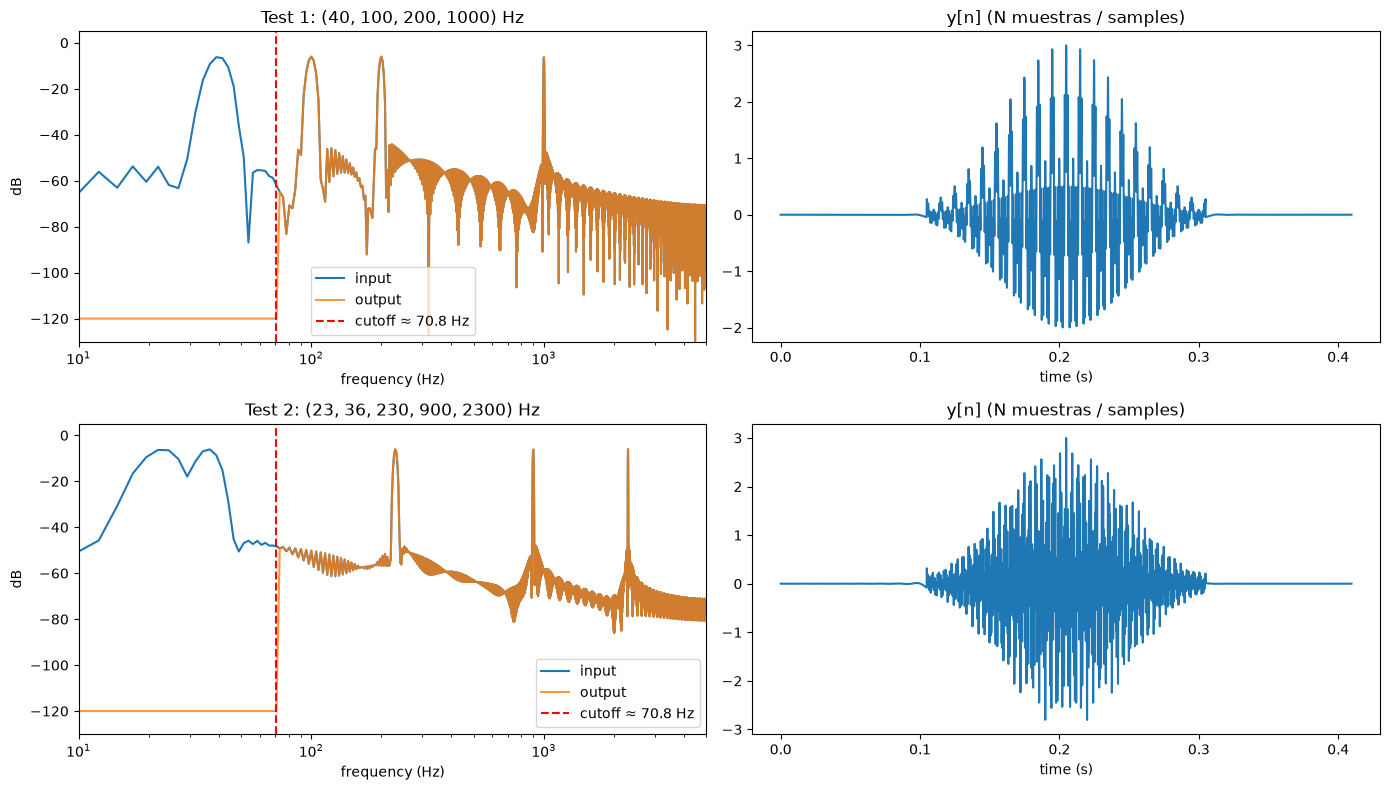

In [18]:
# ✏️ Corrección E3 - 3.2 / Correction E3 - 3.2

fs = 10000
M = 2001                  # impar / odd
N = 4096                  # potencia de 2, N ≥ M / power of 2, N ≥ M
tests = [(40, 100, 200, 1000),
         (23, 36, 230, 900, 2300)]

w = get_window('hamming', M)
freqs = np.arange(N//2 + 1) * fs / N
cutoff = np.ceil(70.0 * N / fs) * fs / N

fig, axes = plt.subplots(len(tests), 2, figsize=(14, 8))

for i, freqs_in in enumerate(tests):
    n = np.arange(M)
    x = sum(np.cos(2*np.pi*f/fs*n) for f in freqs_in)

    y = suppress_freq_dft_model(x, fs, N)

    # Espectros con la misma escala / Spectra on the same scale
    mX, _ = dftAnal(x, w, N)
    mY = 20 * np.log10(np.maximum(np.abs(np.fft.rfft(y)) / sum(w), 1e-12))

    k = [int(round(f * N / fs)) for f in freqs_in]
    print(f"Test {i+1}: len(y) = {len(y)}")
    for f, kk in zip(freqs_in, k):
        print(f"   {f:5d} Hz:  mX = {mX[kk]:7.1f} dB   mY = {mY[kk]:7.1f} dB")

    axes[i, 0].plot(freqs, mX, label='input')
    axes[i, 0].plot(freqs, mY, label='output', alpha=0.8)
    axes[i, 0].axvline(cutoff, color='r', ls='--', label=f'cutoff ≈ {cutoff:.1f} Hz')
    axes[i, 0].set_xscale('log')
    axes[i, 0].set_xlim(10, fs/2)
    axes[i, 0].set_ylim(-130, 5)
    axes[i, 0].set_title(f"Test {i+1}: {freqs_in} Hz")
    axes[i, 0].set_xlabel("frequency (Hz)")
    axes[i, 0].set_ylabel("dB")
    axes[i, 0].legend()

    axes[i, 1].plot(np.arange(N) / fs, y)
    axes[i, 1].set_title("y[n] (N muestras / samples)")
    axes[i, 1].set_xlabel("time (s)")

plt.tight_layout()
plt.show()

### ✏️ Respuestas E3 - 3.3: Preguntas conceptuales / Conceptual questions

**1. ¿Por qué −120 dB y no 0? / Why −120 dB and not 0?**

- **Tu respuesta / Your answer:** *"you need a roof"*. ⚠️ Idea incompleta: −120 dB actúa como un "suelo", no como un techo, y falta explicar por qué 0 no sirve. / Incomplete idea: −120 dB acts as a "floor", not a roof, and the reason 0 doesn't work is missing.
- **ES:** `mX` está en **dB**, y **0 dB no es cero**: $20\log_{10}|X| = 0 \Rightarrow |X| = 1$. Con la ventana normalizada, los picos de las sinusoides valen 0.5 (−6 dB), así que poner esos bins a 0 dB **amplificaría** las bajas frecuencias en lugar de eliminarlas. Comprobado: con 0 dB, $\max|y|$ sube de 3.0 a 5.55. El cero real en dB es $-\infty$, y aunque aquí `dftSynth()` lo aceptaría ($10^{-\infty/20} = 0$), un `-inf` da problemas en gráficas y en cualquier operación posterior (p. ej. $-\infty - (-\infty) = \text{NaN}$). −120 dB equivale a una amplitud de $10^{-6}$: en la práctica es cero, porque queda muy por debajo del ruido de cuantización de 16 bits (≈ −96 dB).
- **EN:** `mX` is in **dB**, and **0 dB is not zero**: $20\log_{10}|X| = 0 \Rightarrow |X| = 1$. With the normalised window, the sinusoid peaks are 0.5 (−6 dB), so setting those bins to 0 dB would **boost** the low frequencies instead of removing them. Checked: with 0 dB, $\max|y|$ rises from 3.0 to 5.55. True zero in dB is $-\infty$, and although `dftSynth()` would accept it here ($10^{-\infty/20} = 0$), `-inf` breaks plots and any later arithmetic (e.g. $-\infty - (-\infty) = \text{NaN}$). −120 dB is an amplitude of $10^{-6}$: effectively zero, well below the 16-bit quantisation noise floor (≈ −96 dB).

**2. Espectros de entrada y salida / Input and output spectra** (gráfica de E3 - 3.2 / plot in E3 - 3.2)

- **Tu respuesta / Your answer:** *"Already proved with the graph… no need to recheck"*. ⚠️ La pregunta pide **describir** lo que cambia y comprobarlo, no solo afirmarlo. Además, que el código imponga la condición no garantiza que el resultado sea el esperado: tu primera versión filtraba por dB y la gráfica lo habría delatado. / The question asks you to **describe** what changes and verify it, not just assert it. Also, the code imposing the condition doesn't guarantee the expected result: your first version filtered by dB, and the plot would have exposed it.
- **ES:** El corte está en el bin $\lceil 70 \cdot 4096/10000 \rceil = 29$, es decir, $29 \cdot 10000/4096 \approx 70.8$ Hz (línea roja). Todos los bins por debajo de ese corte, incluido el 29, caen a −120 dB. Los picos de 40 Hz (test 1) y de 23 y 36 Hz (test 2) desaparecen (de −6 dB a −120 dB). Por encima del corte la salida coincide exactamente con la entrada: 100, 200, 1000 Hz y 230, 900, 2300 Hz siguen en ≈ −6 dB. Un detalle: el corte es tan abrupto que **los lóbulos laterales** de las componentes eliminadas que caen por encima de 70.8 Hz **no se eliminan**. Por ejemplo, la fuga de 40 Hz sigue ahí a ≈ −70 dB en 80 Hz, porque solo se borran bins, no sinusoides completas.
- **EN:** The cutoff is bin $\lceil 70 \cdot 4096/10000 \rceil = 29$, i.e. $29 \cdot 10000/4096 \approx 70.8$ Hz (red line). Every bin up to and including bin 29 drops to −120 dB. The peaks at 40 Hz (test 1) and at 23 and 36 Hz (test 2) disappear (from −6 dB to −120 dB). Above the cutoff the output matches the input exactly: 100, 200, 1000 Hz and 230, 900, 2300 Hz stay at ≈ −6 dB. One detail: the cut is so sharp that the **side lobes** of the removed components lying above 70.8 Hz **are not removed**. For example, the 40 Hz leakage is still there at ≈ −70 dB at 80 Hz, because only bins are erased, not whole sinusoids.

**3. Artefactos en el tiempo / Time-domain artifacts**

- **Tu respuesta / Your answer:** *"No idea"*. ❌ Sin respuesta. / No answer.
- **ES:** Sí. La salida ideal sería $x_{\text{sin 40 Hz}}\cdot w$, que es nula fuera de la ventana. En el centro el error respecto a esa salida ideal es de ≈ $10^{-4}$, pero cerca de los **bordes** sube a ≈ 0.04, y **fuera** de la ventana, donde debería haber ceros (0–0.1 s y 0.3–0.41 s), aparece una oscilación de hasta ≈ 0.04. Se debe a que poner bins a cero equivale a multiplicar $X[k]$ por un filtro ideal $H[k]$ (0 hasta el bin 29 y 1 a partir de ahí), es decir, a una **convolución circular** de $x\cdot w$ con $h[n] = \mathrm{IDFT}(H[k])$. Un escalón abrupto en frecuencia tiene una respuesta impulsional tipo **sinc**: dura todo el buffer de $N$ muestras, decae lentamente (≈ $1/n$) y oscila (fenómeno de **Gibbs**). Al convolucionar, esas oscilaciones se extienden fuera de la ventana. Además, como la convolución es circular, lo que se sale por un extremo vuelve a entrar por el otro (*time aliasing*). Se nota sobre todo en los bordes porque la ventana Hamming **no llega a cero** en sus extremos ($w[0] = 0.08$), así que la señal tiene un salto brusco allí. La propiedad responsable es que $h[n]$ es **larga y no está localizada en el tiempo**, porque $H[k]$ es discontinua: cuanto más abrupto es el filtro en frecuencia, más larga y oscilante es su respuesta en el tiempo.
- **EN:** Yes. The ideal output would be $x_{\text{no 40 Hz}}\cdot w$, which is zero outside the window. In the centre the error against that ideal output is ≈ $10^{-4}$, but near the **edges** it rises to ≈ 0.04, and **outside** the window, where there should be zeros (0–0.1 s and 0.3–0.41 s), an oscillation of up to ≈ 0.04 appears. This happens because zeroing bins is the same as multiplying $X[k]$ by an ideal filter $H[k]$ (0 up to bin 29, 1 from there on), i.e. a **circular convolution** of $x\cdot w$ with $h[n] = \mathrm{IDFT}(H[k])$. A sharp step in frequency has a **sinc**-like impulse response: it spans the whole $N$-sample buffer, decays slowly (≈ $1/n$) and oscillates (**Gibbs** phenomenon). Through the convolution, those oscillations spread outside the window. And since the convolution is circular, whatever leaves one end wraps around into the other (*time aliasing*). It shows mostly at the edges because the Hamming window **doesn't reach zero** at its ends ($w[0] = 0.08$), so the signal has an abrupt jump there. The property responsible is that $h[n]$ is **long and not localised in time**, because $H[k]$ is discontinuous: the sharper the filter is in frequency, the longer and more oscillatory its response in time.

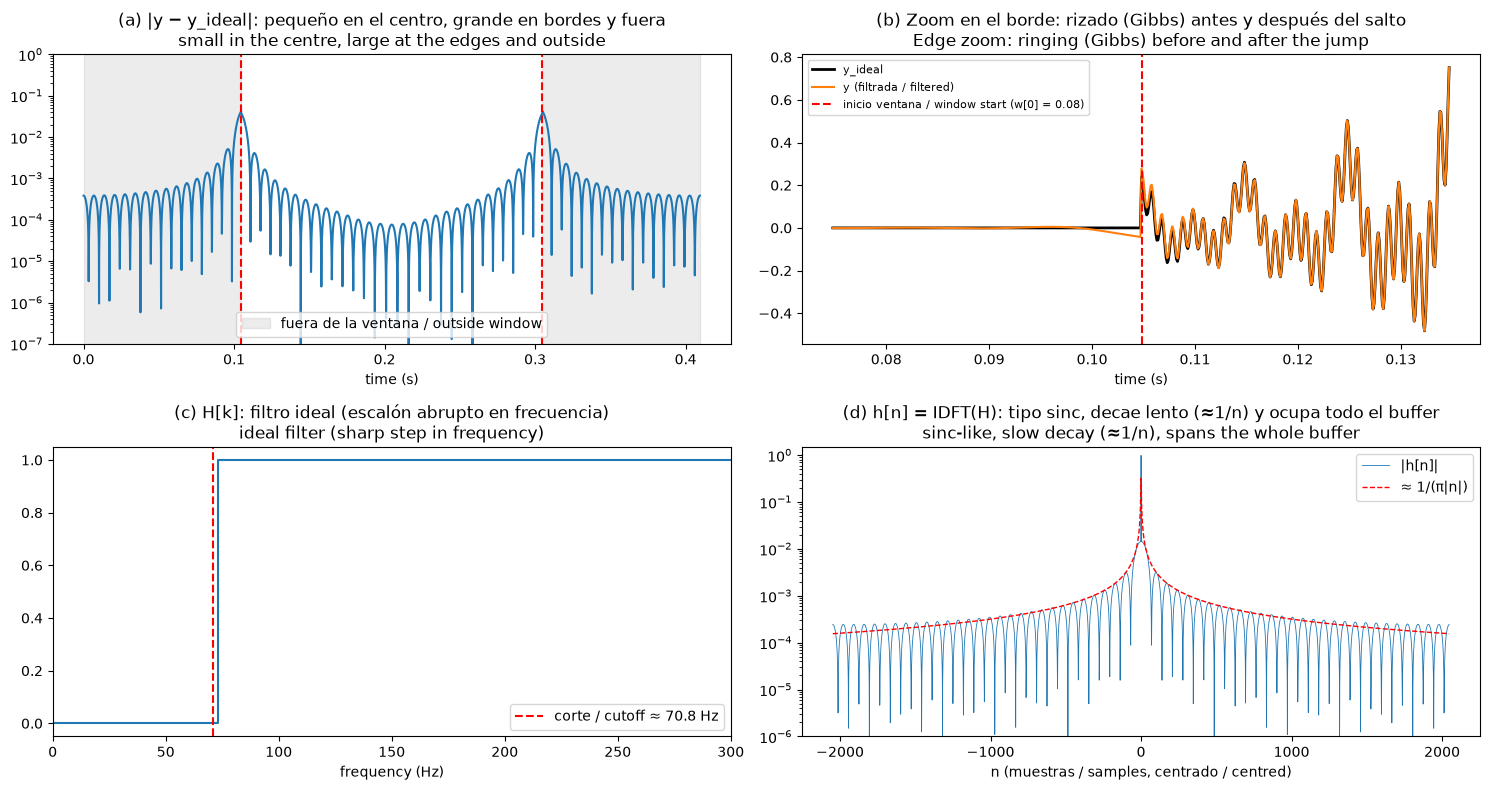

max error centro / centre (±200 muestras/samples): 8.7e-05
max error bordes / edges (primeras 50 muestras/first 50 samples): 3.8e-02
max |y| fuera de la ventana / outside the window: 4.2e-02


In [19]:
# ✏️ Gráfica para E3 - 3.3 (pregunta 3) / Plot for E3 - 3.3 (question 3)

fs, M, N = 10000, 2001, 4096
n = np.arange(M)
x = sum(np.cos(2*np.pi*f/fs*n) for f in (40, 100, 200, 1000))
w = get_window('hamming', M)

# Salida real del filtro / Actual filter output
y = suppress_freq_dft_model(x, fs, N)

# Salida ideal: x sin 40 Hz, enventanada y centrada en el buffer (como hace dftSynth)
# Ideal output: x without 40 Hz, windowed and centred in the buffer (as dftSynth does)
x_ideal = sum(np.cos(2*np.pi*f/fs*n) for f in (100, 200, 1000))
start = N//2 - M//2
y_ideal = np.zeros(N)
y_ideal[start:start + M] = x_ideal * w
err = np.abs(y - y_ideal)

# Respuesta impulsional del filtro: H[k] = 0 en bins <= 29 (y sus espejos), 1 en el resto
# Filter impulse response: H[k] = 0 at bins <= 29 (and their mirrors), 1 elsewhere
cutoff_bin = int(np.ceil(70.0 * N / fs))
H = np.ones(N)
H[:cutoff_bin + 1] = 0
H[N - cutoff_bin:] = 0
h = np.real(np.fft.fftshift(np.fft.ifft(H)))
m = np.arange(-N//2, N//2)

t = np.arange(N) / fs
edges = [start / fs, (start + M - 1) / fs]

fig, axes = plt.subplots(2, 2, figsize=(15, 8))

# (a) Error en todo el buffer / Error over the whole buffer
ax = axes[0, 0]
ax.semilogy(t, err + 1e-12)
for e in edges:
    ax.axvline(e, color='r', ls='--')
ax.axvspan(0, edges[0], color='gray', alpha=0.15, label='fuera de la ventana / outside window')
ax.axvspan(edges[1], t[-1], color='gray', alpha=0.15)
ax.set_ylim(1e-7, 1)
ax.set_title("(a) |y − y_ideal|: pequeño en el centro, grande en bordes y fuera\n"
             "small in the centre, large at the edges and outside")
ax.set_xlabel("time (s)")
ax.legend(loc='lower center')

# (b) Zoom en el borde izquierdo / Zoom on the left edge
ax = axes[0, 1]
z = slice(start - 300, start + 300)
ax.plot(t[z], y_ideal[z], 'k', lw=2, label='y_ideal')
ax.plot(t[z], y[z], 'C1', label='y (filtrada / filtered)')
ax.axvline(edges[0], color='r', ls='--', label='inicio ventana / window start (w[0] = 0.08)')
ax.set_title("(b) Zoom en el borde: rizado (Gibbs) antes y después del salto\n"
             "Edge zoom: ringing (Gibbs) before and after the jump")
ax.set_xlabel("time (s)")
ax.legend(loc='upper left', fontsize=8)

# (c) H[k]: escalón abrupto / sharp step
ax = axes[1, 0]
ax.plot(np.arange(N//2 + 1) * fs / N, H[:N//2 + 1], drawstyle='steps-post')
ax.set_xlim(0, 300)
ax.axvline(cutoff_bin * fs / N, color='r', ls='--', label=f'corte / cutoff ≈ {cutoff_bin*fs/N:.1f} Hz')
ax.set_title("(c) H[k]: filtro ideal (escalón abrupto en frecuencia)\n"
             "ideal filter (sharp step in frequency)")
ax.set_xlabel("frequency (Hz)")
ax.legend()

# (d) h[n]: respuesta impulsional larga y oscilante / long, oscillating impulse response
ax = axes[1, 1]
ax.semilogy(m, np.abs(h) + 1e-12, lw=0.6, label='|h[n]|')
ax.semilogy(m[m != 0], 2 * cutoff_bin / N / (np.pi * np.abs(m[m != 0]) * 2 * cutoff_bin / N), 'r--',
            lw=1, label='≈ 1/(π|n|)')
ax.set_ylim(1e-6, 1.5)
ax.set_title("(d) h[n] = IDFT(H): tipo sinc, decae lento (≈1/n) y ocupa todo el buffer\n"
             "sinc-like, slow decay (≈1/n), spans the whole buffer")
ax.set_xlabel("n (muestras / samples, centrado / centred)")
ax.legend()

plt.tight_layout()
plt.show()

print(f"max error centro / centre (±200 muestras/samples): {err[N//2-200:N//2+200].max():.1e}")
print(f"max error bordes / edges (primeras 50 muestras/first 50 samples): {err[start:start+50].max():.1e}")
print(f"max |y| fuera de la ventana / outside the window: {np.abs(np.r_[y[:start], y[start+M:]]).max():.1e}")


## Part 4 – Window size, FFT size, and zero-padding

The function `zp_fft_size_expt()` should compute three magnitude spectra of the same input signal using different window sizes and FFT sizes, to illustrate the effects of these parameters on spectral resolution and interpolation.

Use a 512-sample input signal at `fs = 1000 Hz` with a Hamming analysis window. The three configurations are:

| Config | Window size | FFT size | Effect |
|--------|------------|----------|--------|
| 1 | 256 | 256 | baseline |
| 2 | 512 | 512 | longer window → better frequency resolution |
| 3 | 256 | 512 | zero-padding (256 zeros added) → interpolated spectrum |

Use `dftAnal()` to obtain the positive-half magnitude spectrum (in dB) for each configuration. Return the three spectra as a list.

**Input:** `x` (np.array, 512 samples)
**Output:** list of three magnitude spectra `[mX1, mX2, mX3]`


In [20]:
# E3 - 4.1: Complete the function zp_fft_size_expt()

def zp_fft_size_expt(x, window_size=[256, 512, 256], FFT_size=[256, 512, 512]):
    """compute magnitude spectra of x with different window sizes and FFT sizes.

    Args:
        x (np.array): input signal (512 samples long)

    Returns:
        list with magnitude spectra (np.array)
    """

    ### Your code here
    mag_spectra = []
    for M, N in zip(window_size, FFT_size):
        w = get_window('hamming', M)          # ventana de M muestras / M-sample window
        mX, _ = dftAnal(x[:M], w, N)          # primeras M muestras; dftAnal rellena con ceros hasta N
                                              # first M samples; dftAnal zero-pads up to N
        mag_spectra.append(mX)                # N/2 + 1 bins en dB / N/2 + 1 bins in dB
    return mag_spectra

Test case for `zp_fft_size_expt()`:

Use `x = 0.2*np.cos(2*np.pi*200*n) + 0.2*np.cos(2*np.pi*400*n)` where `n = np.arange(512)/fs` and `fs = 1000 Hz`. Call with default arguments:

```python
mag_spectra = zp_fft_size_expt(x)
```

Plot all three spectra on a common frequency axis (Hz) with different colors. You should observe:
- `mag_spectra[2]` is an interpolated version of `mag_spectra[0]` (zero-padding interpolates the DFT)
- `mag_spectra[1]` has a **narrower mainlobe** than `mag_spectra[0]` (longer window → better frequency resolution)


M=256, N=256: len(mX) = 129, Δf = fs/N = 3.906 Hz, pico/peak bin 51 → 199.219 Hz (-20.26 dB)
M=512, N=512: len(mX) = 257, Δf = fs/N = 1.953 Hz, pico/peak bin 205 → 400.391 Hz (-20.27 dB)
M=256, N=512: len(mX) = 257, Δf = fs/N = 1.953 Hz, pico/peak bin 205 → 400.391 Hz (-20.06 dB)


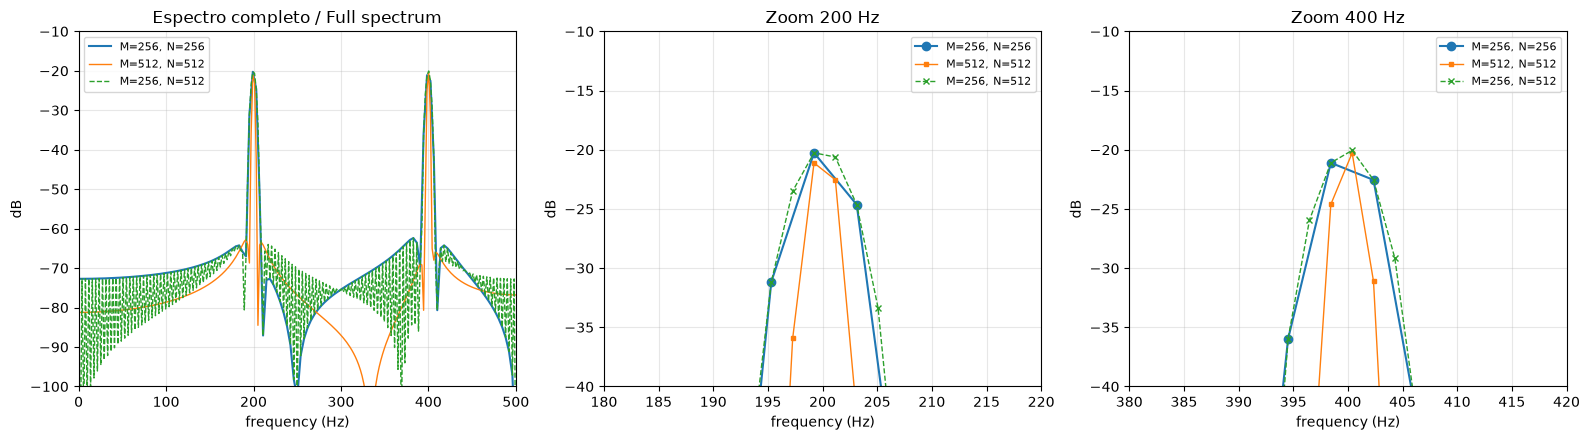

In [21]:
# E3 - 4.2: Generate the test signal above, call zp_fft_size_expt(), and plot the three magnitude
#            spectra on a common frequency axis with different colors. Add a legend.

### Your code here
fs = 1000
n = np.arange(512) / fs
x = 0.2*np.cos(2*np.pi*200*n) + 0.2*np.cos(2*np.pi*400*n)

window_size = [256, 512, 256]
FFT_size = [256, 512, 512]
mag_spectra = zp_fft_size_expt(x, window_size, FFT_size)

labels = [f"M={M}, N={N}" for M, N in zip(window_size, FFT_size)]
styles = [dict(color='C0', marker='o', ms=6, lw=1.5),
          dict(color='C1', marker='s', ms=3, lw=1),
          dict(color='C2', marker='x', ms=5, lw=1, ls='--')]

for mX, N, lab in zip(mag_spectra, FFT_size, labels):
    k_peak = np.argmax(mX)
    print(f"{lab}: len(mX) = {len(mX)}, Δf = fs/N = {fs/N:.3f} Hz, "
          f"pico/peak bin {k_peak} → {k_peak*fs/N:.3f} Hz ({mX[k_peak]:.2f} dB)")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (lo, hi), title in zip(axes, [(0, fs/2), (180, 220), (380, 420)],
                               ["Espectro completo / Full spectrum",
                                "Zoom 200 Hz", "Zoom 400 Hz"]):
    for mX, N, lab, st in zip(mag_spectra, FFT_size, labels, styles):
        f = np.arange(len(mX)) * fs / N
        ax.plot(f, mX, label=lab, **(st if lo > 0 else {k: v for k, v in st.items() if k not in ('marker', 'ms')}))
    ax.set_xlim(lo, hi)
    ax.set_ylim(-100 if lo == 0 else -40, -10)
    ax.set_title(title)
    ax.set_xlabel("frequency (Hz)")
    ax.set_ylabel("dB")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

**E3 - 4.3: Conceptual questions (answer here)**

1. Compare `mag_spectra[0]` (M=256, N=256) and `mag_spectra[2]` (M=256, N=512). What is the relationship between them? Measure the bin spacing (in Hz) for each and explain why they differ or agree despite having the same window.
2. Compare `mag_spectra[0]` (M=256) and `mag_spectra[1]` (M=512). Which one has a narrower mainlobe? What physical quantity determines mainlobe width, and why does a longer window help?
3. Zero-padding does not add new information about the signal. Given that, what exactly does it contribute to the spectrum representation? When would zero-padding be useful in practice?
4. For frequency estimation (finding the peak bin and converting to Hz), which of the three spectra gives the most accurate estimate? Justify your answer based on what you observe in the plots.


### ✏️ Respuestas E3 - 4.3: Preguntas conceptuales / Conceptual questions

**1. `mag_spectra[0]` (M=256, N=256) vs `mag_spectra[2]` (M=256, N=512)**

- **ES:** `mag_spectra[2]` es una **versión interpolada** de `mag_spectra[0]`: los bins pares de la primera coinciden exactamente con la segunda (`mag_spectra[2][::2] == mag_spectra[0]`, con una diferencia máxima de ≈ $10^{-12}$ dB), y los bins impares son puntos nuevos entre cada dos. La separación entre bins es $\Delta f = f_s/N$: $1000/256 = 3.906$ Hz para la primera y $1000/512 = 1.953$ Hz para la segunda. Son distintas porque dependen de **N** (el tamaño de la FFT), no de la ventana. Pero la **forma** del espectro (ancho del lóbulo principal, lóbulos laterales) es la misma, porque la ventana es la misma (M=256): ambas muestrean la misma DTFT continua de $x\cdot w$, la primera con 129 puntos y la segunda con 257.
- **EN:** `mag_spectra[2]` is an **interpolated version** of `mag_spectra[0]`: the even bins of the former match the latter exactly (`mag_spectra[2][::2] == mag_spectra[0]`, max difference ≈ $10^{-12}$ dB), and the odd bins are new points in between. The bin spacing is $\Delta f = f_s/N$: $1000/256 = 3.906$ Hz for the first and $1000/512 = 1.953$ Hz for the second. They differ because spacing depends on **N** (the FFT size), not on the window. But the spectrum's **shape** (main lobe width, side lobes) is the same, because the window is the same (M=256): both sample the same continuous DTFT of $x\cdot w$, the first with 129 points and the second with 257.

**2. `mag_spectra[0]` (M=256) vs `mag_spectra[1]` (M=512)**

- **ES:** `mag_spectra[1]` (M=512) tiene el lóbulo principal **más estrecho**, la mitad. El ancho del lóbulo principal lo fija la **duración de la ventana en el tiempo**, $M/f_s$ segundos. Para una Hamming mide 4 bins de $f_s/M$: $4\cdot1000/256 = 15.6$ Hz con M=256 y $4\cdot1000/512 = 7.8$ Hz con M=512 (medido: primer nulo a ±7.8 Hz y ±3.9 Hz). Es el principio de incertidumbre tiempo-frecuencia: ver la señal durante más tiempo permite distinguir frecuencias más cercanas. Con una ventana larga, dos sinusoides que difieren poco en frecuencia tienen tiempo de desfasarse y se pueden separar, mientras que con una ventana corta sus lóbulos se solapan y se ven como un solo pico. Es **resolución real**: información nueva sobre la señal, porque usa el doble de muestras.
- **EN:** `mag_spectra[1]` (M=512) has the **narrower** main lobe, half as wide. Main lobe width is set by the **window's duration in time**, $M/f_s$ seconds. For a Hamming it spans 4 bins of $f_s/M$: $4\cdot1000/256 = 15.6$ Hz with M=256 and $4\cdot1000/512 = 7.8$ Hz with M=512 (measured: first null at ±7.8 Hz and ±3.9 Hz). This is the time-frequency uncertainty principle: observing the signal for longer lets you tell closer frequencies apart. With a long window, two sinusoids that differ slightly in frequency have time to drift out of phase and can be separated; with a short window their lobes overlap and they look like a single peak. This is **real resolution**: new information about the signal, since it uses twice as many samples.

**3. ¿Qué aporta el zero-padding? / What does zero-padding contribute?**

- **ES:** Solo **muestrea más densamente** el mismo espectro continuo (la DTFT de $x \cdot w$), es decir, interpola. No estrecha el lóbulo principal ni separa picos que antes estaban juntos (eso solo lo hace una M mayor, como en la pregunta 2). Sirve para:
  - **Ver mejor la forma real del espectro**: con N=M los bins pueden caer en los lados del lóbulo o en los nulos de los lóbulos laterales, y el espectro parece distinto de lo que es (en la gráfica, la curva azul con N=256 apenas muestra lóbulos laterales y la verde los revela).
  - **Estimar mejor la frecuencia y la amplitud de un pico**: el máximo puede caer entre dos bins (*scalloping*), y con más bins el pico medido está más cerca del real. Ej.: a 400 Hz, con N=256 el pico vale −21.1 dB; con N=512, −20.1 dB (el valor real es −20 dB).
  - **Usar una FFT** cuando M no es potencia de 2 (p. ej. M=2001 → N=4096, como en la Parte 3).
  - **Evitar el *time aliasing*** en la convolución circular cuando se filtra en frecuencia.
- **EN:** It only **samples the same continuous spectrum more densely** (the DTFT of $x \cdot w$), i.e. it interpolates. It doesn't narrow the main lobe or separate peaks that were merged (only a larger M does that, as in question 2). It's useful to:
  - **See the real shape of the spectrum**: with N=M the bins may land on the sides of the lobe or on side-lobe nulls, making the spectrum look different from what it is (in the plot, the blue N=256 curve barely shows side lobes and the green one reveals them).
  - **Better estimate a peak's frequency and amplitude**: the maximum can fall between two bins (*scalloping*), and with more bins the measured peak is closer to the true one. E.g. at 400 Hz, N=256 gives a peak of −21.1 dB; N=512 gives −20.1 dB (true value: −20 dB).
  - **Use an FFT** when M is not a power of 2 (e.g. M=2001 → N=4096, as in Part 3).
  - **Avoid time aliasing** from circular convolution when filtering in the frequency domain.

**4. ¿Qué espectro estima mejor la frecuencia? / Which spectrum gives the best frequency estimate?**

- **ES:** Pico más alto de cada configuración (bin $k$ → $k\,f_s/N$):

  | Config | $\Delta f$ | 200 Hz → | error | 400 Hz → | error |
  |---|---|---|---|---|---|
  | M=256, N=256 | 3.906 Hz | 199.22 Hz | −0.78 Hz | 398.44 Hz | −1.56 Hz |
  | M=512, N=512 | 1.953 Hz | 199.22 Hz | −0.78 Hz | 400.39 Hz | +0.39 Hz |
  | M=256, N=512 | 1.953 Hz | 199.22 Hz | −0.78 Hz | 400.39 Hz | +0.39 Hz |

  La **peor** es M=256, N=256: el error máximo posible es $\Delta f/2 = 1.95$ Hz. Las dos con N=512 dan **la misma estimación** (error máximo $0.98$ Hz), porque la precisión de "coger el bin máximo" depende solo de la rejilla de bins ($f_s/N$), no de M. El zero-padding mejora la precisión tanto como duplicar la ventana. Entre esas dos, la mejor es **M=512, N=512**: da la misma precisión y además tiene el lóbulo más estrecho, así que es más robusta si hay picos cercanos o ruido (un pico vecino desplazaría menos el máximo). Para afinar todavía más sin aumentar N se usa **interpolación parabólica** alrededor del bin máximo (se verá en el modelo sinusoidal).
- **EN:** Highest peak of each configuration (bin $k$ → $k\,f_s/N$): see the table above. The **worst** is M=256, N=256: the maximum possible error is $\Delta f/2 = 1.95$ Hz. Both N=512 configurations give **the same estimate** (maximum error $0.98$ Hz), because the precision of "take the maximum bin" depends only on the bin grid ($f_s/N$), not on M. Zero-padding improves precision as much as doubling the window. Of those two, the best is **M=512, N=512**: same precision plus the narrower main lobe, so it's more robust with nearby peaks or noise (a neighbouring peak would shift the maximum less). To refine further without increasing N, use **parabolic interpolation** around the maximum bin (covered in the sinusoidal model).

---
## ✏️ Extra: *Time aliasing*

- **ES:** Multiplicar dos DFTs de $N$ puntos equivale a una convolución **circular** en el tiempo: $X_1[k]X_2[k] \Leftrightarrow x_1 \circledast_N x_2$. Si $x_1$ mide $M$ y $x_2$ mide $L$, la convolución lineal mide $M+L-1$ muestras. Si $N < M+L-1$, lo que no cabe al final del buffer **vuelve a entrar por el principio** y se suma: eso es el *time aliasing*. Se evita con zero-padding hasta $N \ge M+L-1$.
- **EN:** Multiplying two $N$-point DFTs is a **circular** convolution in time: $X_1[k]X_2[k] \Leftrightarrow x_1 \circledast_N x_2$. If $x_1$ is $M$ long and $x_2$ is $L$ long, the linear convolution is $M+L-1$ samples long. If $N < M+L-1$, whatever doesn't fit at the end of the buffer **wraps around to the start** and adds up: that's *time aliasing*. Zero-padding up to $N \ge M+L-1$ avoids it.

**Fila 1 / Row 1:** ejemplo sencillo: señal de $M=64$ muestras filtrada con un eco que decae, $h[n]$ de $L=32$ muestras / simple example: a 64-sample signal filtered with a decaying echo, $h[n]$ of 32 samples.
**Fila 2 / Row 2:** el filtro de la Parte 3, separando Gibbs y *time aliasing* / the Part 3 filter, separating Gibbs and time aliasing.

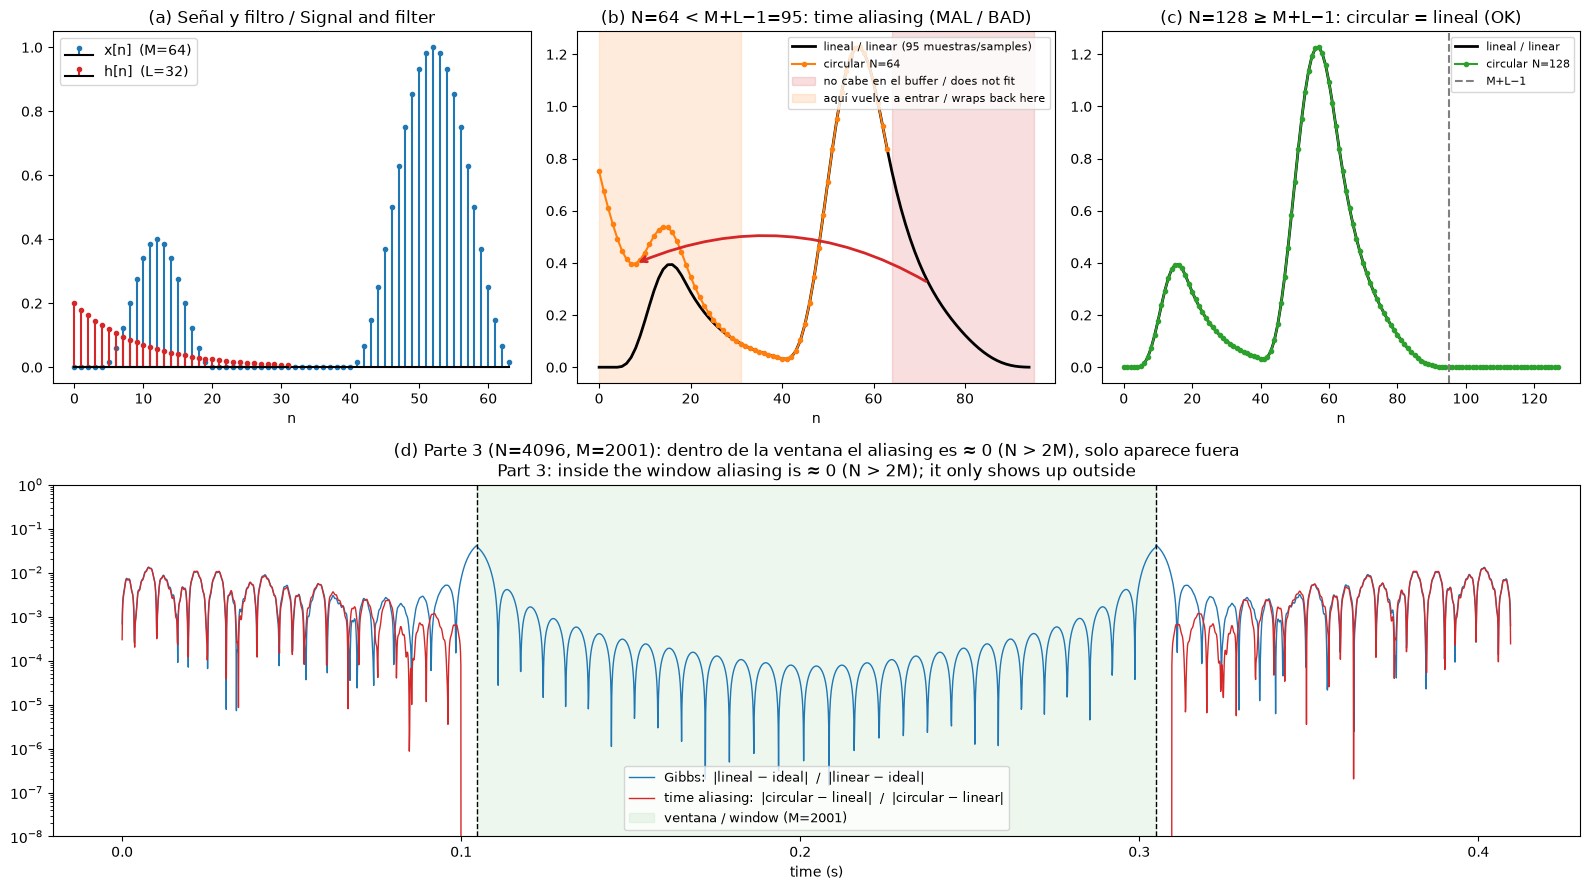

Ejemplo / Example:  max|circular − lineal| primeras 31 muestras/first samples (N=64) = 0.752   |   N=128: 1.6e-16
Parte 3 / Part 3:   aliasing dentro/inside = 4.2e-15, fuera/outside = 1.3e-02


In [22]:
# ✏️ Extra: gráfica de time aliasing / time aliasing plot

def circ_conv(x, h, N):
    """Convolución circular de N puntos vía DFT / N-point circular convolution via the DFT"""
    return np.real(np.fft.ifft(np.fft.fft(x, N) * np.fft.fft(h, N)))

# ---------- Fila 1: ejemplo sencillo / Row 1: simple example ----------
M, L = 64, 32
nn = np.arange(M)
xs = (0.4 * np.sin(np.pi*(nn - 4)/16)**2 * ((nn >= 4) & (nn < 20))      # pulso pequeño al principio / small pulse at the start
      + 1.0 * np.sin(np.pi*(nn - 40)/24)**2 * (nn >= 40))       # pulso grande al final / big pulse at the end
hs = 0.2 * 0.9**np.arange(L)                      # eco que decae / decaying echo
y_lin = np.convolve(xs, hs)                       # M+L-1 = 95 muestras / samples

N_bad, N_ok = M, 128                              # 64 < 95 (aliasing)   |   128 >= 95 (OK)
y_bad = circ_conv(xs, hs, N_bad)
y_ok = circ_conv(xs, hs, N_ok)

# ---------- Fila 2: filtro de la Parte 3 / Row 2: Part 3 filter ----------
fs3, M3, N3 = 10000, 2001, 4096
n3 = np.arange(M3)
w3 = get_window('hamming', M3)
start3 = N3//2 - M3//2
xw = np.zeros(N3);   xw[start3:start3+M3] = sum(np.cos(2*np.pi*f/fs3*n3) for f in (40, 100, 200, 1000)) * w3
ideal = np.zeros(N3); ideal[start3:start3+M3] = sum(np.cos(2*np.pi*f/fs3*n3) for f in (100, 200, 1000)) * w3
cb = int(np.ceil(70.0 * N3 / fs3))
H3 = np.ones(N3); H3[:cb+1] = 0; H3[N3-cb:] = 0
h3 = np.fft.fftshift(np.real(np.fft.ifft(H3)))   # centrada en N/2 / centred at N/2
y3_circ = np.real(np.fft.ifft(np.fft.fft(xw) * H3))
y3_lin = np.convolve(xw, h3)[N3//2:N3//2 + N3]    # misma porción de tiempo, sin vuelta / same time span, no wrap
gibbs = np.abs(y3_lin - ideal)
alias = np.abs(y3_circ - y3_lin)
t3 = np.arange(N3) / fs3

fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 3)

ax = fig.add_subplot(gs[0, 0])
ax.stem(np.arange(M), xs, linefmt='C0-', markerfmt='C0.', basefmt='k-', label=f'x[n]  (M={M})')
ax.stem(np.arange(L), hs, linefmt='C3-', markerfmt='C3.', basefmt='k-', label=f'h[n]  (L={L})')
ax.set_title("(a) Señal y filtro / Signal and filter")
ax.set_xlabel("n"); ax.legend()

ax = fig.add_subplot(gs[0, 1])
ax.plot(np.arange(len(y_lin)), y_lin, 'k', lw=2, label=f'lineal / linear ({M+L-1} muestras/samples)')
ax.plot(np.arange(N_bad), y_bad, 'C1o-', ms=3, label=f'circular N={N_bad}')
ax.axvspan(N_bad, len(y_lin), color='C3', alpha=0.15, label='no cabe en el buffer / does not fit')
ax.axvspan(0, L-1, color='C1', alpha=0.15, label='aquí vuelve a entrar / wraps back here')
ax.annotate('', xy=(8, y_bad[8]), xytext=(N_bad + 8, y_lin[N_bad + 8]),
            arrowprops=dict(arrowstyle='->', color='C3', lw=2, connectionstyle='arc3,rad=0.25'))
ax.set_title(f"(b) N={N_bad} < M+L−1={M+L-1}: time aliasing (MAL / BAD)")
ax.set_xlabel("n"); ax.legend(fontsize=8, loc='upper right')

ax = fig.add_subplot(gs[0, 2])
ax.plot(np.arange(len(y_lin)), y_lin, 'k', lw=2, label='lineal / linear')
ax.plot(np.arange(N_ok), y_ok, 'C2o-', ms=3, label=f'circular N={N_ok}')
ax.axvline(M+L-1, color='gray', ls='--', label='M+L−1')
ax.set_title(f"(c) N={N_ok} ≥ M+L−1: circular = lineal (OK)")
ax.set_xlabel("n"); ax.legend(fontsize=8)

ax = fig.add_subplot(gs[1, :])
ax.semilogy(t3, gibbs + 1e-17, 'C0', lw=1, label='Gibbs:  |lineal − ideal|  /  |linear − ideal|')
ax.semilogy(t3, alias + 1e-17, 'C3', lw=1, label='time aliasing:  |circular − lineal|  /  |circular − linear|')
for e in (start3/fs3, (start3+M3-1)/fs3):
    ax.axvline(e, color='k', ls='--', lw=1)
ax.axvspan(start3/fs3, (start3+M3-1)/fs3, color='C2', alpha=0.08, label='ventana / window (M=2001)')
ax.set_ylim(1e-8, 1)
ax.set_title("(d) Parte 3 (N=4096, M=2001): dentro de la ventana el aliasing es ≈ 0 (N > 2M), solo aparece fuera\n"
             "Part 3: inside the window aliasing is ≈ 0 (N > 2M); it only shows up outside")
ax.set_xlabel("time (s)"); ax.legend(loc='lower center', fontsize=9)

plt.tight_layout()
plt.show()

print(f"Ejemplo / Example:  max|circular − lineal| primeras {L-1} muestras/first samples (N={N_bad}) = "
      f"{np.abs(y_bad[:L-1] - y_lin[:L-1]).max():.3f}   |   N={N_ok}: {np.abs(y_ok[:M+L-1] - y_lin).max():.1e}")
inside = slice(start3, start3 + M3)
print(f"Parte 3 / Part 3:   aliasing dentro/inside = {alias[inside].max():.1e}, "
      f"fuera/outside = {np.r_[alias[:start3], alias[start3+M3:]].max():.1e}")
